**PROJECT TITLE** : ***Explainable Credit Risk Scoring and Decisioning System Using Machine Learning***

**PROBLEM STATEMENT** : *Financial institutions need to accurately assess applicant credit risk before extending credit while balancing potential losses and business opportunities.
This project develops an explainable machine-learning system to predict Good/Bad credit performance and estimate an applicant’s probability of Bad credit performance.
The system further converts these predictions into a credit score, risk band, and decision-support recommendation using a traditional credit scorecard and an ML-based challenger model.*


*HELOC stands for Home Equity Line of Credit.*

*It is a type of revolving credit that allows a homeowner to borrow money using the equity in their home as collateral.*

*Unlike a conventional fixed loan where the borrower receives a fixed amount upfront, a HELOC generally provides a credit line from which the borrower can draw funds as required, subject to the terms of the facility.*

*For a lender, extending a HELOC creates credit risk because the borrower may fail to meet their repayment obligations.*

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [ ]:
file_path = "/content/drive/MyDrive/heloc_dataset_v1.csv"
df = pd.read_csv(file_path)

df.head()


,RiskPerformance,ExternalRiskEstimate,MSinceOldestTradeOpen,MSinceMostRecentTradeOpen,AverageMInFile,NumSatisfactoryTrades,NumTrades60Ever2DerogPubRec,NumTrades90Ever2DerogPubRec,PercentTradesNeverDelq,MSinceMostRecentDelq,...,PercentInstallTrades,MSinceMostRecentInqexcl7days,NumInqLast6M,NumInqLast6Mexcl7days,NetFractionRevolvingBurden,NetFractionInstallBurden,NumRevolvingTradesWBalance,NumInstallTradesWBalance,NumBank2NatlTradesWHighUtilization,PercentTradesWBalance
0,Bad,55,144,4,84,20,3,0,83,2,...,43,0,0,0,33,-8,8,1,1,69
1,Bad,61,58,15,41,2,4,4,100,-7,...,67,0,0,0,0,-8,0,-8,-8,0
2,Bad,67,66,5,24,9,0,0,100,-7,...,44,0,4,4,53,66,4,2,1,86
3,Bad,66,169,1,73,28,1,1,93,76,...,57,0,5,4,72,83,6,4,3,91
4,Bad,81,333,27,132,12,0,0,100,-7,...,25,0,1,1,51,89,3,1,0,80


|  # | Feature                                | Type                 | Description                                                                                                        | Credit-risk relevance                                                                     |
| -: | -------------------------------------- | -------------------- | ------------------------------------------------------------------------------------------------------------------ | ----------------------------------------------------------------------------------------- |
|  1 | **RiskPerformance**                    | Target / Categorical | Indicates the applicant's observed credit performance: **Good** or **Bad**.                                        | **Target variable** to be predicted.                                                      |
|  2 | **ExternalRiskEstimate**               | Numerical            | External estimate of the applicant's overall credit risk based on credit-history information.                      | Higher/lower values can distinguish stronger and weaker credit profiles.                  |
|  3 | **MSinceOldestTradeOpen**              | Numerical            | Number of months since the applicant's oldest recorded credit trade was opened.                                    | Represents **length of credit history**.                                                  |
|  4 | **MSinceMostRecentTradeOpen**          | Numerical            | Number of months since the applicant's most recently opened credit trade.                                          | Captures **recent credit-account activity**.                                              |
|  5 | **AverageMInFile**                     | Numerical            | Average number of months that the applicant's credit trades/accounts have been on file.                            | Represents the **average age of credit history**.                                         |
|  6 | **NumSatisfactoryTrades**              | Numerical            | Number of credit trades classified as satisfactory.                                                                | Indicates the amount of **positive credit history**.                                      |
|  7 | **NumTrades60Ever2DerogPubRec**        | Numerical / Coded    | Credit-history measure involving trades with **60+ day delinquency** and derogatory/public-record information.     | Captures historical adverse credit behavior.                                              |
|  8 | **NumTrades90Ever2DerogPubRec**        | Numerical / Coded    | Credit-history measure involving trades with **90+ day delinquency** and derogatory/public-record information.     | Captures more severe adverse credit history.                                              |
|  9 | **PercentTradesNeverDelq**             | Numerical (%)        | Percentage of trades that have **never been delinquent**.                                                          | Higher values generally indicate a stronger repayment history.                            |
| 10 | **MSinceMostRecentDelq**               | Numerical            | Number of months since the applicant's most recent delinquency.                                                    | Indicates **recency of adverse payment behavior**.                                        |
| 11 | **MaxDelq2PublicRecLast12M**           | Coded / Ordinal      | Maximum delinquency-related category associated with the applicant's recent 12-month credit/public-record history. | Captures **recent severity of adverse credit behavior**.                                  |
| 12 | **MaxDelqEver**                        | Coded / Ordinal      | Maximum delinquency category observed over the applicant's credit history.                                         | Captures the applicant's **worst historical delinquency level**.                          |
| 13 | **NumTotalTrades**                     | Numerical            | Total number of credit trades recorded for the applicant.                                                          | Represents the overall size of the applicant's recorded credit history.                   |
| 14 | **NumTradesOpeninLast12M**             | Numerical            | Number of credit trades opened during the previous 12 months.                                                      | Measures **recent credit activity**.                                                      |
| 15 | **PercentInstallTrades**               | Numerical (%)        | Percentage of trades that are installment trades.                                                                  | Describes the applicant's **credit portfolio composition**.                               |
| 16 | **MSinceMostRecentInqexcl7days**       | Numerical            | Number of months since the most recent credit inquiry, excluding inquiries from the previous 7 days.               | Measures **recency of credit inquiries**.                                                 |
| 17 | **NumInqLast6M**                       | Numerical            | Number of credit inquiries during the previous six months.                                                         | Can indicate **recent credit-seeking activity**.                                          |
| 18 | **NumInqLast6Mexcl7days**              | Numerical            | Number of credit inquiries during the previous six months excluding inquiries from the most recent seven days.     | Provides another measure of **recent credit-seeking behavior**.                           |
| 19 | **NetFractionRevolvingBurden**         | Numerical (%)        | Measure of the applicant's **revolving-credit burden/utilization**.                                                | Important indicator of outstanding revolving-credit pressure.                             |
| 20 | **NetFractionInstallBurden**           | Numerical (%)        | Measure of the applicant's **installment-credit burden**.                                                          | Indicates the relative burden associated with installment obligations.                    |
| 21 | **NumRevolvingTradesWBalance**         | Numerical            | Number of revolving credit trades that currently have a balance.                                                   | Indicates how many revolving accounts are carrying balances.                              |
| 22 | **NumInstallTradesWBalance**           | Numerical            | Number of installment trades that currently have a balance.                                                        | Indicates outstanding installment-credit obligations.                                     |
| 23 | **NumBank2NatlTradesWHighUtilization** | Numerical / Coded    | Number of relevant bank/national credit trades associated with high utilization.                                   | Captures **high-utilization credit behavior**.                                            |
| 24 | **PercentTradesWBalance**              | Numerical (%)        | Percentage of the applicant's credit trades that currently have a balance.                                         | Indicates the extent to which the applicant's credit accounts carry outstanding balances. |


| Credit-risk category              | Features                                                                                                                        |
| --------------------------------- | ------------------------------------------------------------------------------------------------------------------------------- |
| **Overall Credit Risk**           | `ExternalRiskEstimate`                                                                                                          |
| **Credit History Age**            | `MSinceOldestTradeOpen`, `MSinceMostRecentTradeOpen`, `AverageMInFile`                                                          |
| **Positive Credit History**       | `NumSatisfactoryTrades`, `PercentTradesNeverDelq`                                                                               |
| **Delinquency / Adverse History** | `NumTrades60Ever2DerogPubRec`, `NumTrades90Ever2DerogPubRec`, `MSinceMostRecentDelq`, `MaxDelq2PublicRecLast12M`, `MaxDelqEver` |
| **Credit Activity**               | `NumTotalTrades`, `NumTradesOpeninLast12M`                                                                                      |
| **Credit Portfolio Composition**  | `PercentInstallTrades`                                                                                                          |
| **Credit Inquiries**              | `MSinceMostRecentInqexcl7days`, `NumInqLast6M`, `NumInqLast6Mexcl7days`                                                         |
| **Revolving Credit Burden**       | `NetFractionRevolvingBurden`, `NumRevolvingTradesWBalance`                                                                      |
| **Installment Credit Burden**     | `NetFractionInstallBurden`, `NumInstallTradesWBalance`                                                                          |
| **High Credit Utilization**       | `NumBank2NatlTradesWHighUtilization`                                                                                            |
| **Overall Outstanding Balances**  | `PercentTradesWBalance`                                                                                                         |
| **Target**                        | `RiskPerformance`                                                                                                               |


In [ ]:
df.shape

(10459, 24)

<Axes: xlabel='RiskPerformance'>

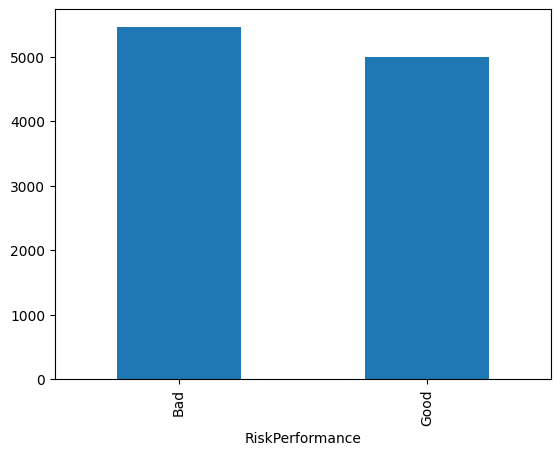

In [ ]:
df["RiskPerformance"].value_counts().plot(kind="bar")

In [ ]:
df["RiskPerformance"].value_counts(normalize=True) * 100

,proportion
RiskPerformance,
Bad,52.194282
Good,47.805718


In [ ]:
df.isnull().sum()

,0
RiskPerformance,0
ExternalRiskEstimate,0
MSinceOldestTradeOpen,0
MSinceMostRecentTradeOpen,0
AverageMInFile,0
NumSatisfactoryTrades,0
NumTrades60Ever2DerogPubRec,0
NumTrades90Ever2DerogPubRec,0
PercentTradesNeverDelq,0
MSinceMostRecentDelq,0


In [ ]:
special_values = [-7, -8, -9]

for col in df.columns:
    counts = df[col].value_counts()
    print(f"\n{col}")
    print(counts[counts.index.isin(special_values)])


RiskPerformance
Series([], Name: count, dtype: int64)

ExternalRiskEstimate
ExternalRiskEstimate
-9    598
Name: count, dtype: int64

MSinceOldestTradeOpen
MSinceOldestTradeOpen
-9    588
-8    239
Name: count, dtype: int64

MSinceMostRecentTradeOpen
MSinceMostRecentTradeOpen
-9    588
Name: count, dtype: int64

AverageMInFile
AverageMInFile
-9    588
Name: count, dtype: int64

NumSatisfactoryTrades
NumSatisfactoryTrades
-9    588
Name: count, dtype: int64

NumTrades60Ever2DerogPubRec
NumTrades60Ever2DerogPubRec
-9    588
Name: count, dtype: int64

NumTrades90Ever2DerogPubRec
NumTrades90Ever2DerogPubRec
-9    588
Name: count, dtype: int64

PercentTradesNeverDelq
PercentTradesNeverDelq
-9    588
Name: count, dtype: int64

MSinceMostRecentDelq
MSinceMostRecentDelq
-7    4664
-9     588
-8     176
Name: count, dtype: int64

MaxDelq2PublicRecLast12M
MaxDelq2PublicRecLast12M
-9    588
Name: count, dtype: int64

MaxDelqEver
MaxDelqEver
-9    588
Name: count, dtype: int64

NumTotalTrades
Num

| Feature                              |      `-7` |      `-8` |    `-9` | Main observation                  |
| ------------------------------------ | --------: | --------: | ------: | --------------------------------- |
| `RiskPerformance`                    |         0 |         0 |       0 | Target has no special codes       |
| `ExternalRiskEstimate`               |         0 |         0 | **598** | Special values present            |
| `MSinceOldestTradeOpen`              |         0 |       239 | **588** | Both `-8` and `-9`                |
| `MSinceMostRecentTradeOpen`          |         0 |         0 | **588** | Only `-9`                         |
| `AverageMInFile`                     |         0 |         0 | **588** | Only `-9`                         |
| `NumSatisfactoryTrades`              |         0 |         0 | **588** | Only `-9`                         |
| `NumTrades60Ever2DerogPubRec`        |         0 |         0 | **588** | Only `-9`                         |
| `NumTrades90Ever2DerogPubRec`        |         0 |         0 | **588** | Only `-9`                         |
| `PercentTradesNeverDelq`             |         0 |         0 | **588** | Only `-9`                         |
| `MSinceMostRecentDelq`               | **4,664** |       176 |     588 | Very high special-value frequency |
| `MaxDelq2PublicRecLast12M`           |         0 |         0 | **588** | Only `-9`                         |
| `MaxDelqEver`                        |         0 |         0 | **588** | Only `-9`                         |
| `NumTotalTrades`                     |         0 |         0 | **588** | Only `-9`                         |
| `NumTradesOpeninLast12M`             |         0 |         0 | **588** | Only `-9`                         |
| `PercentInstallTrades`               |         0 |         0 | **588** | Only `-9`                         |
| `MSinceMostRecentInqexcl7days`       | **1,855** |       476 |     588 | Large special-value presence      |
| `NumInqLast6M`                       |         0 |         0 | **588** | Only `-9`                         |
| `NumInqLast6Mexcl7days`              |         0 |         0 | **588** | Only `-9`                         |
| `NetFractionRevolvingBurden`         |         0 |       186 | **588** | `-8` and `-9`                     |
| `NetFractionInstallBurden`           |         0 | **3,419** | **588** | Very large `-8` presence          |
| `NumRevolvingTradesWBalance`         |         0 |       156 | **588** | `-8` and `-9`                     |
| `NumInstallTradesWBalance`           |         0 |       861 | **588** | `-8` and `-9`                     |
| `NumBank2NatlTradesWHighUtilization` |         0 |       583 | **588** | `-8` and `-9`                     |
| `PercentTradesWBalance`              |         0 |        18 | **588** | `-8` and `-9`                     |


In [ ]:
cols = df.columns.drop("RiskPerformance")

all_minus9 = (df[cols] == -9).all(axis=1)

print("Rows where ALL features are -9:")
print(all_minus9.sum())

Rows where ALL features are -9:
588


In [ ]:
df.loc[all_minus9, "RiskPerformance"].value_counts()

,count
RiskPerformance,
Bad,323
Good,265


In [ ]:
import numpy as np
import pandas as pd

# Make a copy of the raw dataset
df_clean = df.copy()

# --------------------------------------------------
# 1. Identify predictor columns
# --------------------------------------------------

feature_cols = df_clean.columns.drop("RiskPerformance")


# --------------------------------------------------
# 2. Remove rows where ALL predictors are -9
# --------------------------------------------------

all_minus9 = (df_clean[feature_cols] == -9).all(axis=1)

print("Rows with all predictors = -9:", all_minus9.sum())

df_clean = df_clean.loc[~all_minus9].copy()


# --------------------------------------------------
# 3. Create indicators for -7
# --------------------------------------------------

df_clean["NoRecentDelq"] = (
    df_clean["MSinceMostRecentDelq"] == -7
).astype(int)

df_clean["NoRecentInquiry"] = (
    df_clean["MSinceMostRecentInqexcl7days"] == -7
).astype(int)


# --------------------------------------------------
# 4. Convert special values to NaN
# --------------------------------------------------

df_clean = df_clean.replace([-7, -8, -9], np.nan)


# --------------------------------------------------
# 5. Check remaining missing values
# --------------------------------------------------

missing = df_clean.isnull().sum()

print("\nRemaining missing values:")
print(missing[missing > 0])


# --------------------------------------------------
# 6. Check final dimensions
# --------------------------------------------------

print("\nFinal shape before imputation:")
print(df_clean.shape)

Rows with all predictors = -9: 588

Remaining missing values:
ExternalRiskEstimate                    10
MSinceOldestTradeOpen                  239
MSinceMostRecentDelq                  4840
MSinceMostRecentInqexcl7days          2331
NetFractionRevolvingBurden             186
NetFractionInstallBurden              3419
NumRevolvingTradesWBalance             156
NumInstallTradesWBalance               861
NumBank2NatlTradesWHighUtilization     583
PercentTradesWBalance                   18
dtype: int64

Final shape before imputation:
(9871, 26)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [ ]:
X = df_clean.drop(columns=["RiskPerformance"])
y = df_clean["RiskPerformance"]

In [ ]:
y = y.map({
    "Good": 0,
    "Bad": 1
})

In [ ]:
print(y.value_counts())

RiskPerformance
1    5136
0    4735
Name: count, dtype: int64


In [ ]:
high_missing_cols = [
    "MSinceMostRecentDelq",
    "MSinceMostRecentInqexcl7days",
    "NetFractionInstallBurden"
]

for col in high_missing_cols:
    X[col + "_Missing"] = X[col].isna().astype(int)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (7896, 28)
Testing : (1975, 28)


In [ ]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

In [ ]:
X_train_imputed = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

In [ ]:
print("Missing values in training set:")
print(X_train_imputed.isnull().sum().sum())

print("\nMissing values in testing set:")
print(X_test_imputed.isnull().sum().sum())

Missing values in training set:
0

Missing values in testing set:
0


In [ ]:
for col in high_missing_cols:
    indicator = col + "_Missing"
    print(f"\n{indicator}")
    print(X_train_imputed[indicator].value_counts())


MSinceMostRecentDelq_Missing
MSinceMostRecentDelq_Missing
0.0    4029
1.0    3867
Name: count, dtype: int64

MSinceMostRecentInqexcl7days_Missing
MSinceMostRecentInqexcl7days_Missing
0.0    6021
1.0    1875
Name: count, dtype: int64

NetFractionInstallBurden_Missing
NetFractionInstallBurden_Missing
0.0    5161
1.0    2735
Name: count, dtype: int64


In [ ]:
print("Final X_train shape:", X_train_imputed.shape)
print("Final X_test shape :", X_test_imputed.shape)
print("Final y_train shape:", y_train.shape)
print("Final y_test shape :", y_test.shape)

Final X_train shape: (7896, 28)
Final X_test shape : (1975, 28)
Final y_train shape: (7896,)
Final y_test shape : (1975,)


In [ ]:
print(X_train_imputed.shape)
print(X_test_imputed.shape)

print("Train missing:",
      X_train_imputed.isnull().sum().sum())

print("Test missing:",
      X_test_imputed.isnull().sum().sum())

(7896, 28)
(1975, 28)
Train missing: 0
Test missing: 0


In [ ]:
# Check for duplicate rows in the cleaned dataset
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 1


In [ ]:
feature_cols = df_clean.columns.drop("RiskPerformance")

print(
    "Duplicate predictor records:",
    df_clean.duplicated(subset=feature_cols).sum()
)

Duplicate predictor records: 1


In [ ]:
print("Before removing duplicate:", df_clean.shape)

df_clean = df_clean.drop_duplicates().copy()

print("After removing duplicate:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Before removing duplicate: (9871, 26)
After removing duplicate: (9870, 26)
Remaining duplicates: 0


In [ ]:
feature_cols = df_clean.columns.drop("RiskPerformance")

range_summary = pd.DataFrame({
    "Min": df_clean[feature_cols].min(),
    "Max": df_clean[feature_cols].max(),
    "Mean": df_clean[feature_cols].mean(),
    "Median": df_clean[feature_cols].median()
})

print(range_summary)

                                     Min    Max        Mean  Median
ExternalRiskEstimate                33.0   94.0   72.061258    72.0
MSinceOldestTradeOpen                2.0  803.0  200.764822   186.0
MSinceMostRecentTradeOpen            0.0  383.0    9.587639     6.0
AverageMInFile                       4.0  383.0   78.773556    76.0
NumSatisfactoryTrades                0.0   79.0   21.121986    20.0
NumTrades60Ever2DerogPubRec          0.0   19.0    0.581256     0.0
NumTrades90Ever2DerogPubRec          0.0   19.0    0.384802     0.0
PercentTradesNeverDelq               0.0  100.0   92.364539    97.0
MSinceMostRecentDelq                 0.0   83.0   21.883499    15.0
MaxDelq2PublicRecLast12M             0.0    9.0    5.758156     6.0
MaxDelqEver                          2.0    8.0    6.374671     6.0
NumTotalTrades                       0.0  104.0   22.635866    21.0
NumTradesOpeninLast12M               0.0   19.0    1.864032     1.0
PercentInstallTrades                 0.0  100.0 

In [ ]:
print(df_clean["RiskPerformance"].value_counts())
print(df_clean["RiskPerformance"].value_counts(normalize=True) * 100)

RiskPerformance
Bad     5135
Good    4735
Name: count, dtype: int64
RiskPerformance
Bad     52.026342
Good    47.973658
Name: proportion, dtype: float64


In [ ]:
numeric_cols = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns.drop("NoRecentDelq", errors="ignore")

outlier_summary = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": outliers,
        "Outlier_%": outliers / len(df_clean) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(outlier_summary.sort_values(
    "Outlier_%",
    ascending=False
))

                               Feature     Q1      Q3     IQR  Lower_Bound  \
6          NumTrades90Ever2DerogPubRec    0.0    0.00    0.00        0.000   
23                     NoRecentInquiry    0.0    0.00    0.00        0.000   
14        MSinceMostRecentInqexcl7days    0.0    3.00    3.00       -4.500   
10                         MaxDelqEver    6.0    8.00    2.00        3.000   
7               PercentTradesNeverDelq   89.0  100.00   11.00       72.500   
2            MSinceMostRecentTradeOpen    3.0   12.00    9.00      -10.500   
5          NumTrades60Ever2DerogPubRec    0.0    1.00    1.00       -1.500   
19          NumRevolvingTradesWBalance    2.0    5.00    3.00       -2.500   
15                        NumInqLast6M    0.0    2.00    2.00       -3.000   
9             MaxDelq2PublicRecLast12M    5.0    7.00    2.00        2.000   
16               NumInqLast6Mexcl7days    0.0    2.00    2.00       -3.000   
3                       AverageMInFile   57.0   96.75   39.75   

In [ ]:
print(
    df_clean[
        [
            "NetFractionRevolvingBurden",
            "NetFractionInstallBurden"
        ]
    ].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
)

       NetFractionRevolvingBurden  NetFractionInstallBurden
count                 9684.000000               6452.000000
mean                    34.858530                 68.537973
std                     28.898009                 24.903776
min                      0.000000                  0.000000
1%                       0.000000                  5.000000
5%                       0.000000                 19.000000
25%                      9.000000                 53.000000
50%                     29.000000                 74.000000
75%                     56.000000                 87.000000
95%                     89.000000                 99.000000
99%                    100.000000                101.000000
max                    232.000000                471.000000


In [ ]:
for col in [
    "NetFractionRevolvingBurden",
    "NetFractionInstallBurden",
    "MSinceOldestTradeOpen"
]:
    print("\n", "="*60)
    print(col)

    print(
        df_clean[col]
        .sort_values(ascending=False)
        .head(10)
    )


NetFractionRevolvingBurden
9422    232.0
6471    165.0
7743    154.0
5743    135.0
8686    131.0
6177    126.0
9756    124.0
369     120.0
310     120.0
1478    118.0
Name: NetFractionRevolvingBurden, dtype: float64

NetFractionInstallBurden
7627    471.0
8541    196.0
1658    190.0
9596    165.0
1705    153.0
1818    152.0
5429    151.0
114     144.0
9042    142.0
5870    140.0
Name: NetFractionInstallBurden, dtype: float64

MSinceOldestTradeOpen
3466    803.0
2005    789.0
8240    604.0
5764    603.0
5136    598.0
5200    590.0
6363    589.0
3954    589.0
7014    586.0
1759    584.0
Name: MSinceOldestTradeOpen, dtype: float64


EXPLORATORY DATA ANALYSIS

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
print("Dataset shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

Dataset shape: (9870, 26)

Columns:
['RiskPerformance', 'ExternalRiskEstimate', 'MSinceOldestTradeOpen', 'MSinceMostRecentTradeOpen', 'AverageMInFile', 'NumSatisfactoryTrades', 'NumTrades60Ever2DerogPubRec', 'NumTrades90Ever2DerogPubRec', 'PercentTradesNeverDelq', 'MSinceMostRecentDelq', 'MaxDelq2PublicRecLast12M', 'MaxDelqEver', 'NumTotalTrades', 'NumTradesOpeninLast12M', 'PercentInstallTrades', 'MSinceMostRecentInqexcl7days', 'NumInqLast6M', 'NumInqLast6Mexcl7days', 'NetFractionRevolvingBurden', 'NetFractionInstallBurden', 'NumRevolvingTradesWBalance', 'NumInstallTradesWBalance', 'NumBank2NatlTradesWHighUtilization', 'PercentTradesWBalance', 'NoRecentDelq', 'NoRecentInquiry']

Data types:
RiskPerformance                        object
ExternalRiskEstimate                  float64
MSinceOldestTradeOpen                 float64
MSinceMostRecentTradeOpen               int64
AverageMInFile                          int64
NumSatisfactoryTrades                   int64
NumTrades60Ever2DerogPub

In [ ]:
#TARGET DISTRIBUTION
target_counts = df_clean["RiskPerformance"].value_counts()

print(target_counts)

print("\nPercentage:")
print(
    df_clean["RiskPerformance"]
    .value_counts(normalize=True) * 100
)

RiskPerformance
Bad     5135
Good    4735
Name: count, dtype: int64

Percentage:
RiskPerformance
Bad     52.026342
Good    47.973658
Name: proportion, dtype: float64


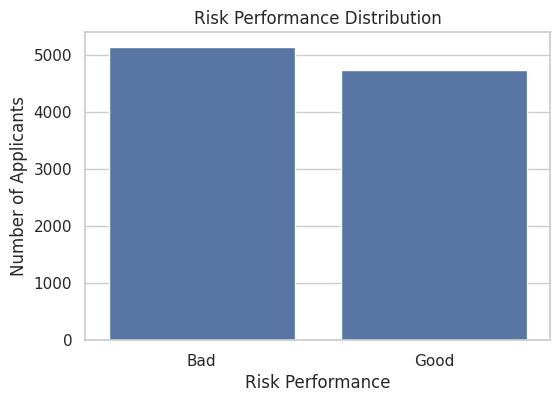

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df_clean,
    x="RiskPerformance"
)

plt.title("Risk Performance Distribution")
plt.xlabel("Risk Performance")
plt.ylabel("Number of Applicants")

plt.show()

In [ ]:
#NUMERICAL SUMMARY STATISTICS
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

summary_stats = df_clean[numeric_cols].describe().T

summary_stats

,count,mean,std,min,25%,50%,75%,max
ExternalRiskEstimate,9860.0,72.061258,9.871962,33.0,64.0,72.0,80.00,94.0
MSinceOldestTradeOpen,9631.0,200.764822,97.950265,2.0,135.0,186.0,257.00,803.0
MSinceMostRecentTradeOpen,9870.0,9.587639,12.963778,0.0,3.0,6.0,12.00,383.0
AverageMInFile,9870.0,78.773556,34.064747,4.0,57.0,76.0,96.75,383.0
NumSatisfactoryTrades,9870.0,21.121986,11.321852,0.0,13.0,20.0,28.00,79.0
NumTrades60Ever2DerogPubRec,9870.0,0.581256,1.238764,0.0,0.0,0.0,1.00,19.0
NumTrades90Ever2DerogPubRec,9870.0,0.384802,0.993265,0.0,0.0,0.0,0.00,19.0
PercentTradesNeverDelq,9870.0,92.364539,11.764615,0.0,89.0,97.0,100.00,100.0
MSinceMostRecentDelq,5030.0,21.883499,20.808694,0.0,5.0,15.0,34.00,83.0
MaxDelq2PublicRecLast12M,9870.0,5.758156,1.644506,0.0,5.0,6.0,7.00,9.0


In [ ]:
#SKEWNESS ANALYSIS
skewness = df_clean[numeric_cols].skew().sort_values(
    ascending=False
)

print(skewness)

MSinceMostRecentTradeOpen             7.089667
NumInqLast6Mexcl7days                 6.417626
NumInqLast6M                          6.157055
NumTrades90Ever2DerogPubRec           5.454521
NumTrades60Ever2DerogPubRec           4.170645
NumBank2NatlTradesWHighUtilization    2.563456
NumInstallTradesWBalance              2.460873
MSinceMostRecentInqexcl7days          2.401679
NumRevolvingTradesWBalance            1.692261
NoRecentInquiry                       1.597802
NumTradesOpeninLast12M                1.543236
MSinceMostRecentDelq                  1.066004
NumTotalTrades                        0.933884
AverageMInFile                        0.920928
NumSatisfactoryTrades                 0.801975
MSinceOldestTradeOpen                 0.711585
PercentInstallTrades                  0.682141
NetFractionRevolvingBurden            0.624287
NoRecentDelq                          0.110010
NetFractionInstallBurden              0.016905
ExternalRiskEstimate                  0.001163
PercentTrades

In [ ]:
skew_table = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

skew_table

,Feature,Skewness
0,MSinceMostRecentTradeOpen,7.089667
1,NumInqLast6Mexcl7days,6.417626
2,NumInqLast6M,6.157055
3,NumTrades90Ever2DerogPubRec,5.454521
4,NumTrades60Ever2DerogPubRec,4.170645
5,NumBank2NatlTradesWHighUtilization,2.563456
6,NumInstallTradesWBalance,2.460873
7,MSinceMostRecentInqexcl7days,2.401679
8,NumRevolvingTradesWBalance,1.692261
9,NoRecentInquiry,1.597802


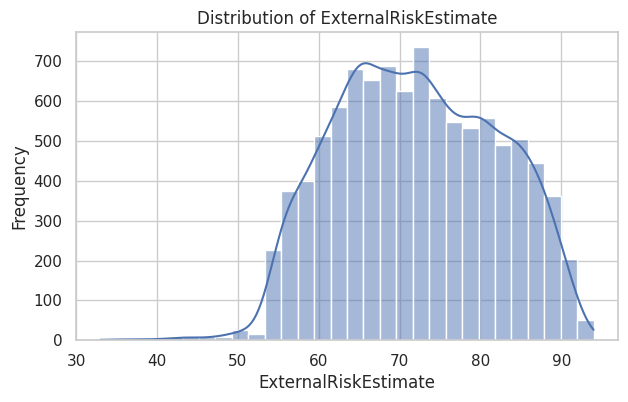

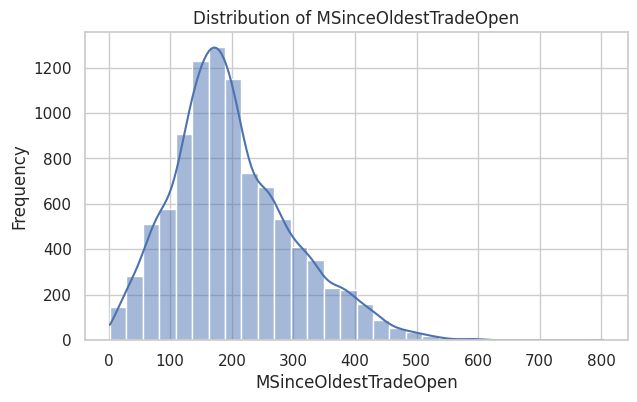

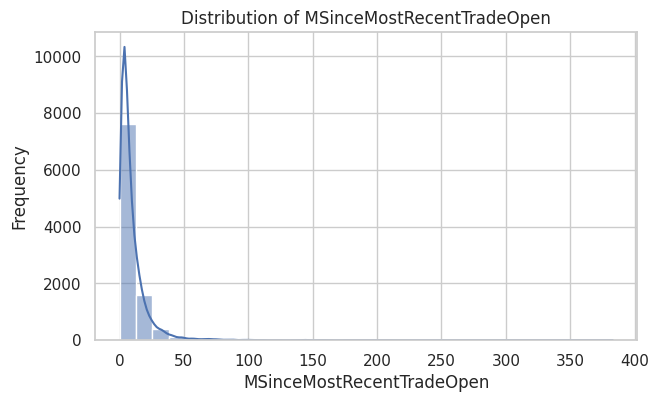

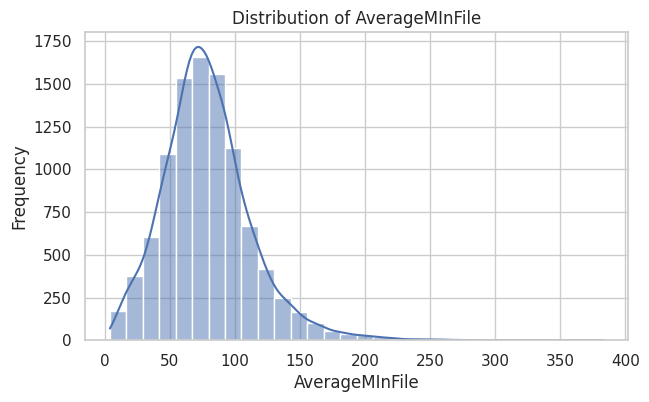

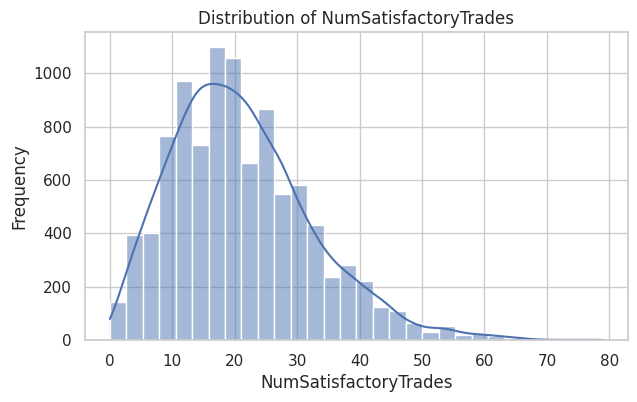

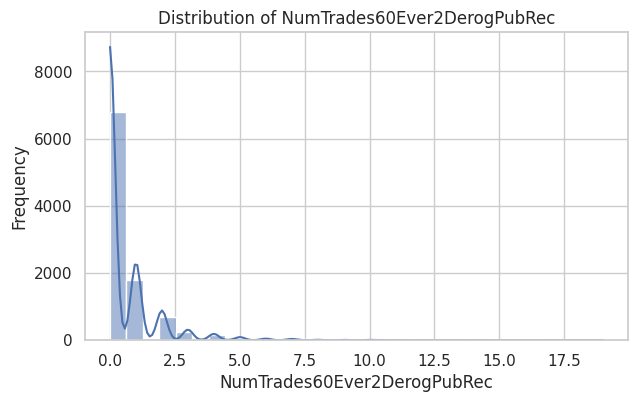

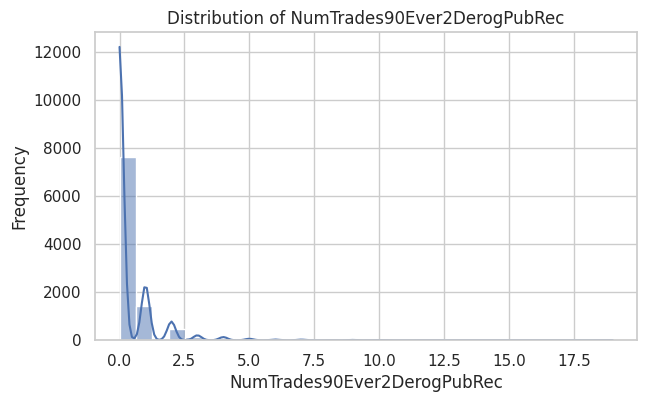

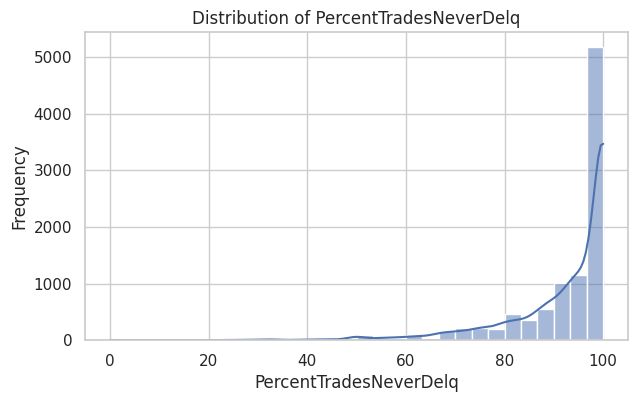

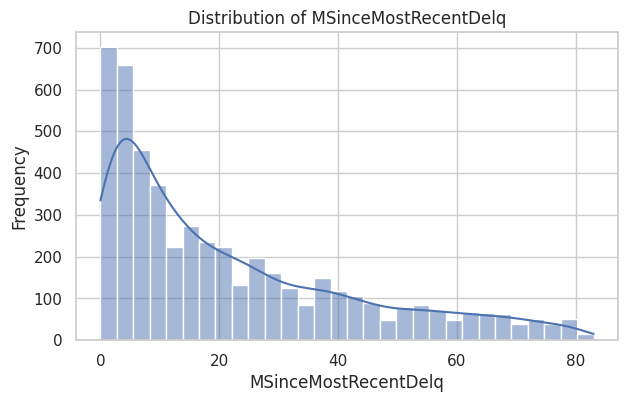

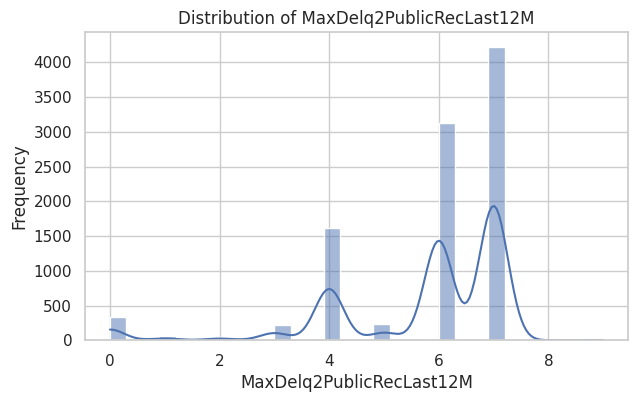

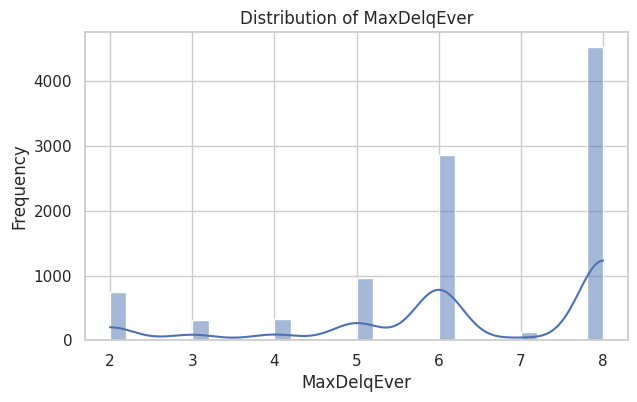

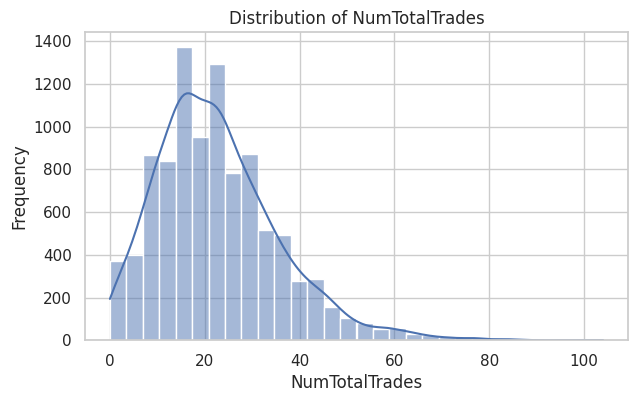

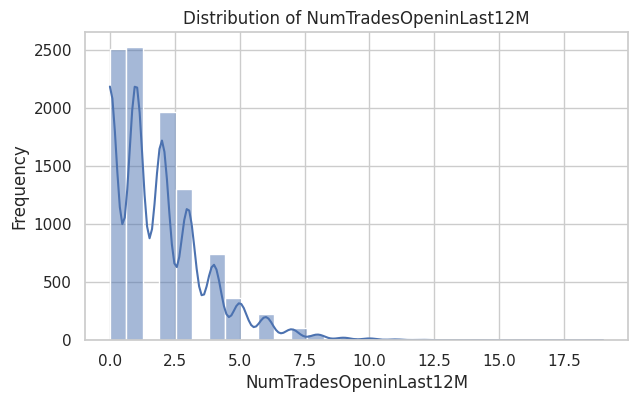

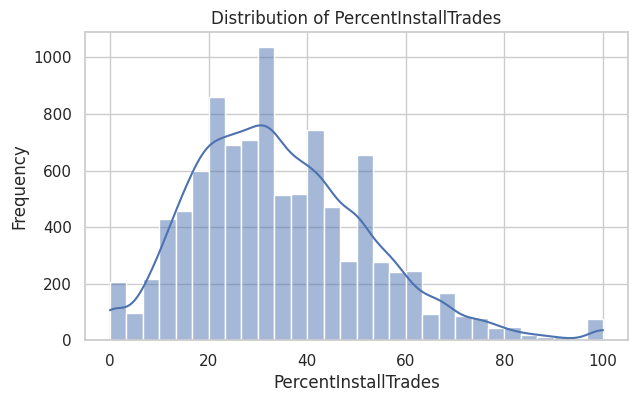

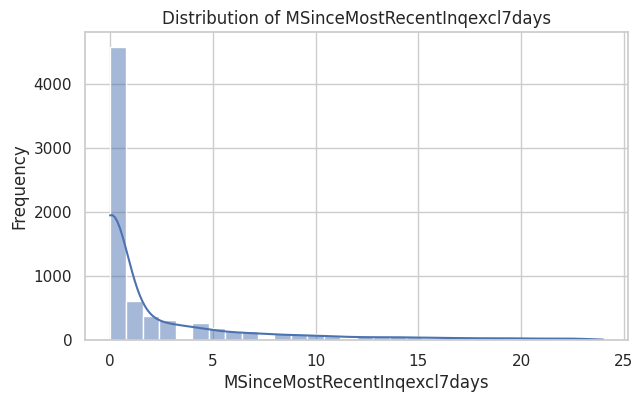

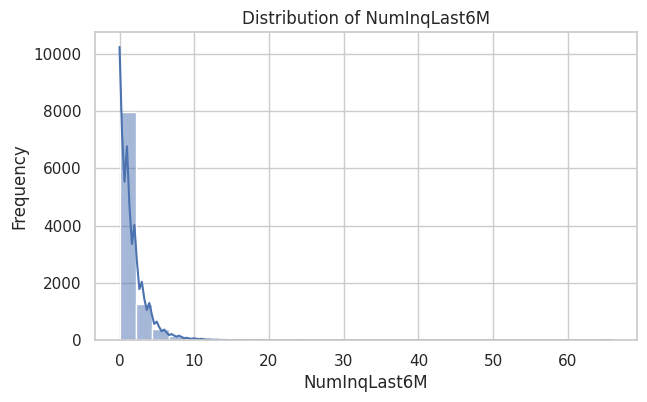

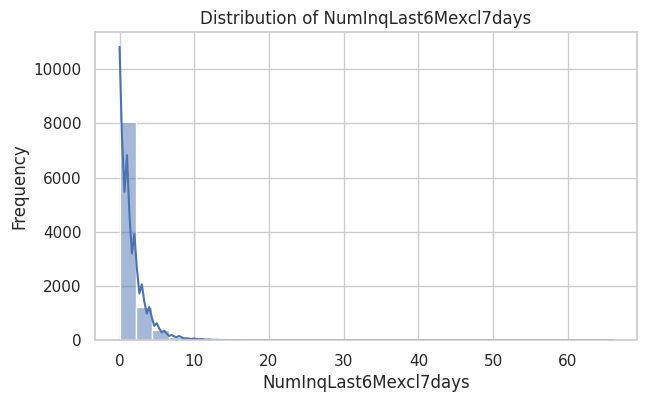

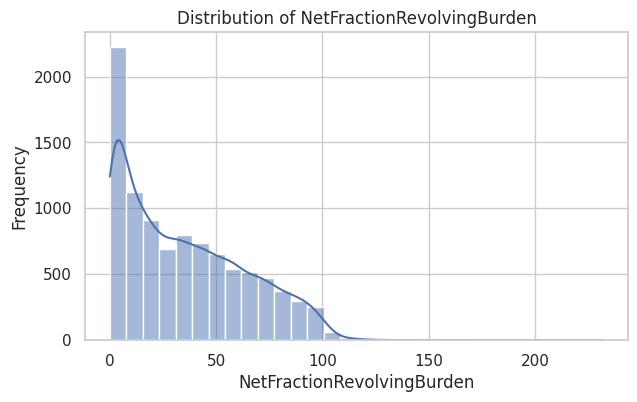

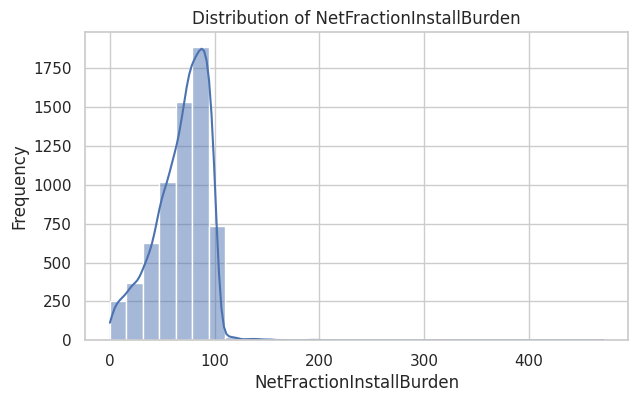

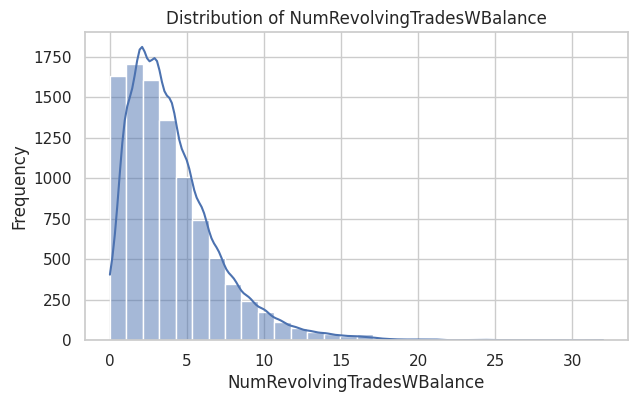

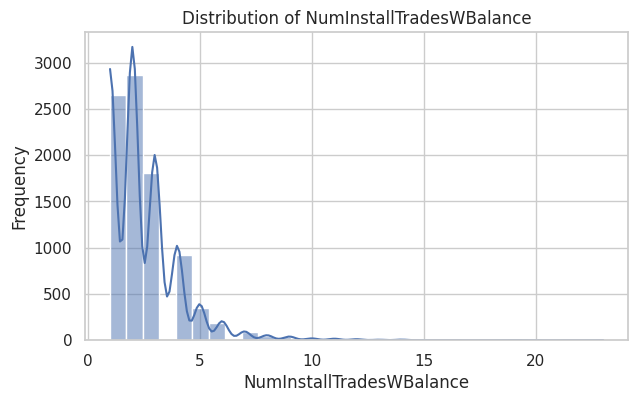

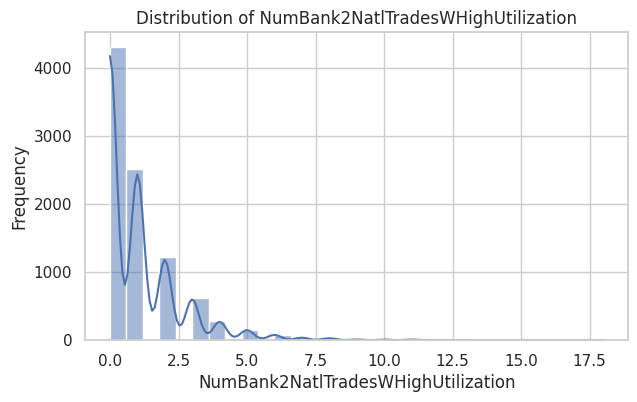

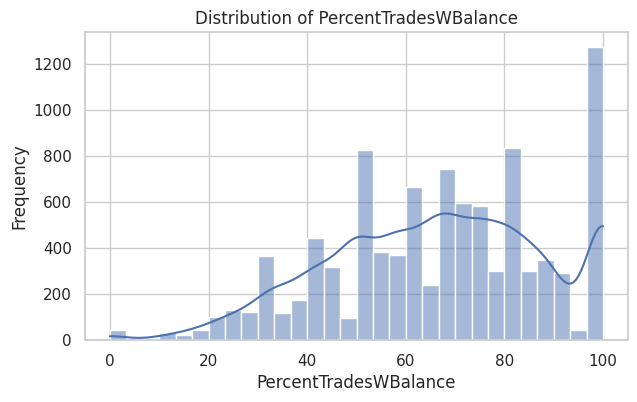

In [ ]:
#DISTRIBUTION OF ALL NUMERIC VALUES
feature_cols = [
    col for col in numeric_cols
    if col not in ["NoRecentDelq", "NoRecentInquiry"]
]

for col in feature_cols:

    plt.figure(figsize=(7,4))

    sns.histplot(
        data=df_clean,
        x=col,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

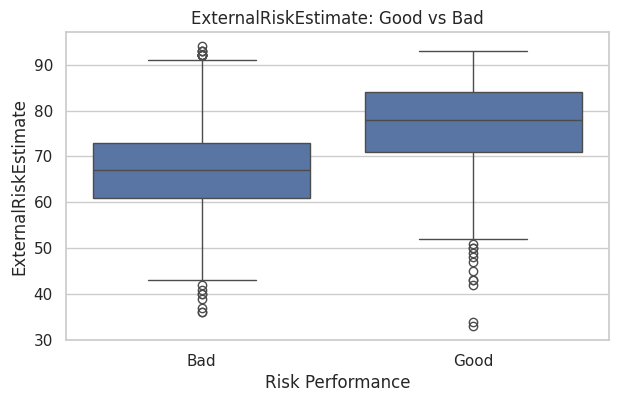

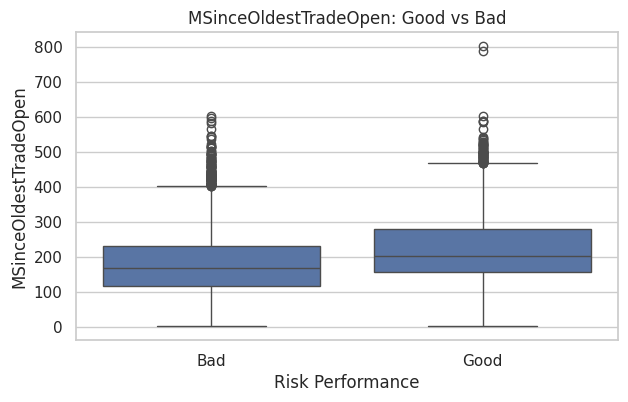

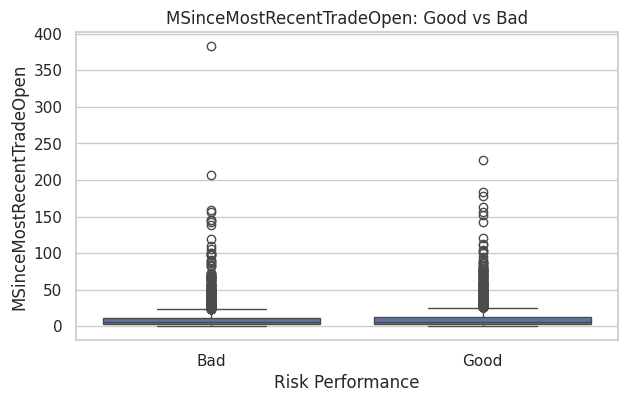

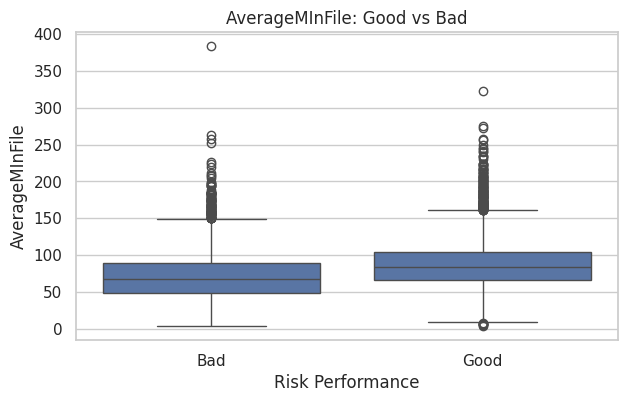

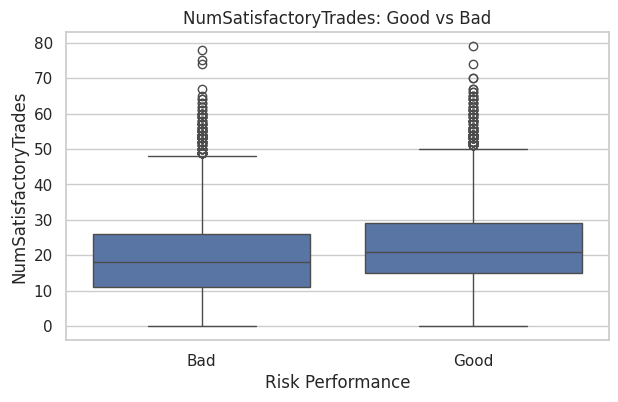

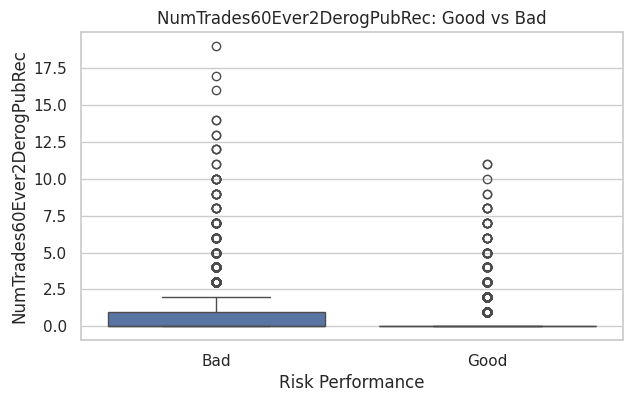

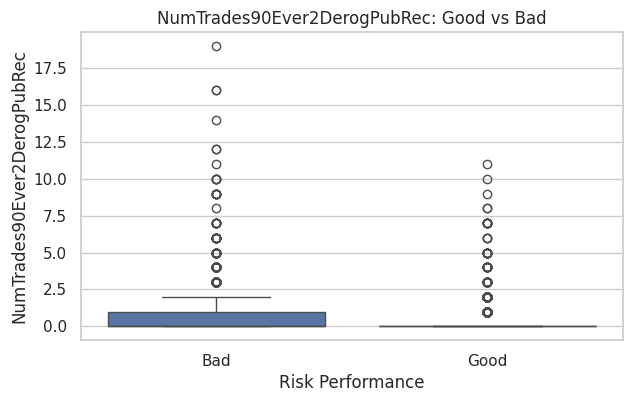

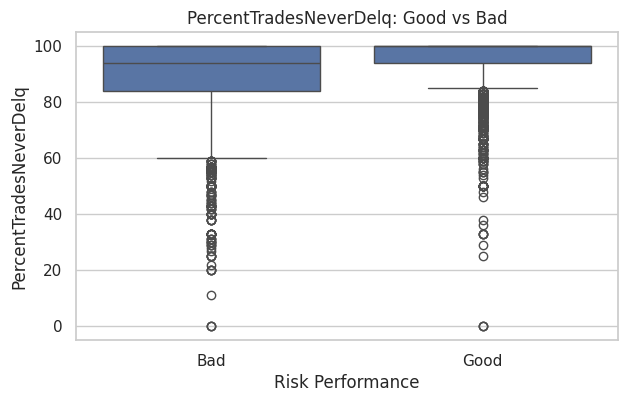

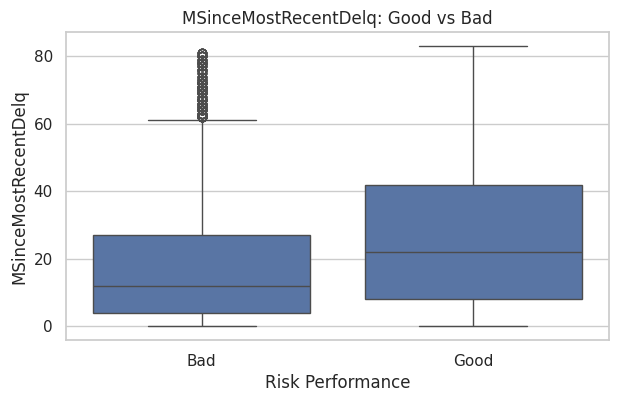

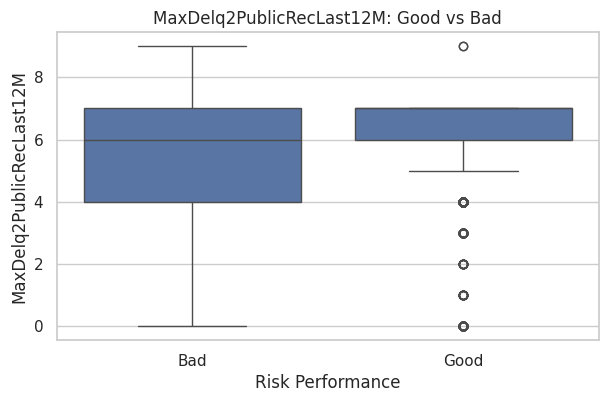

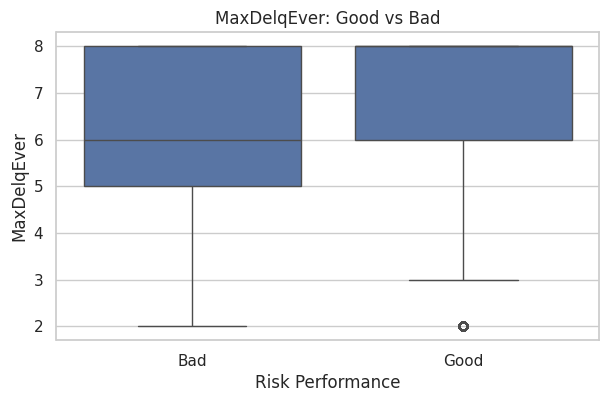

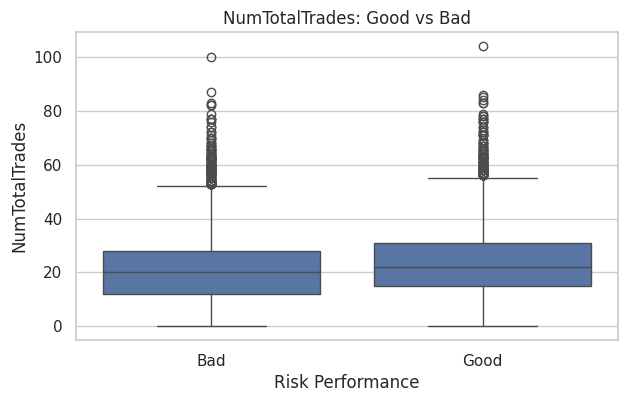

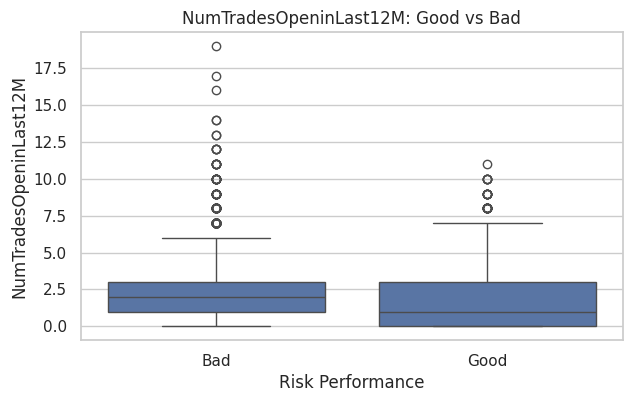

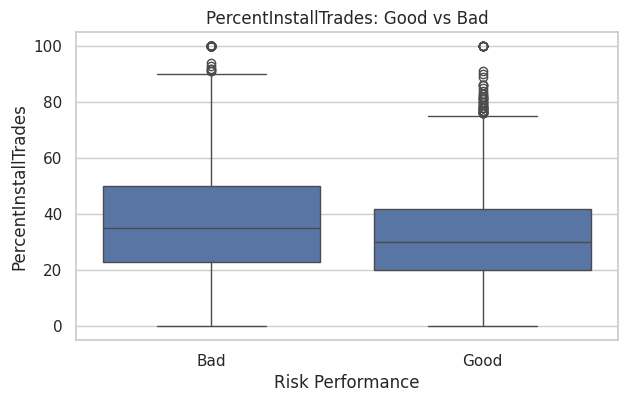

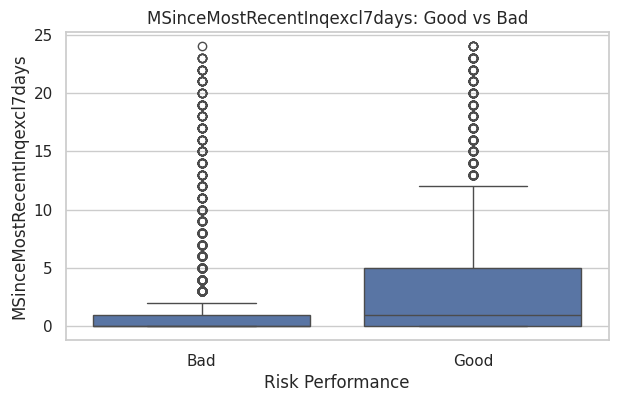

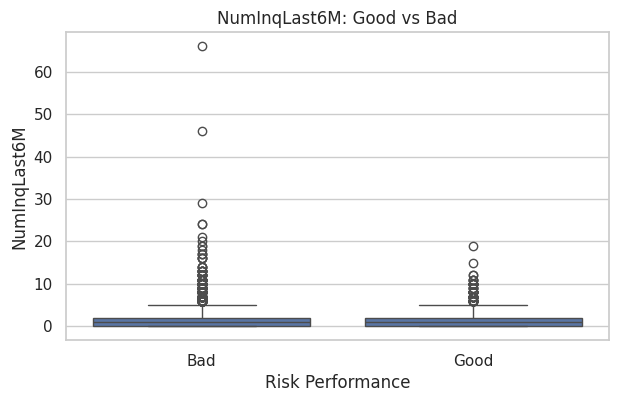

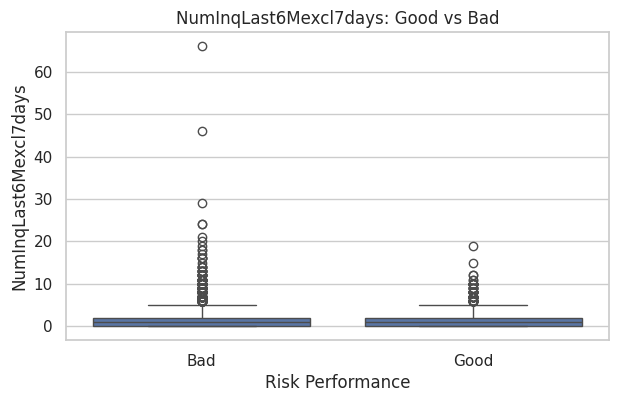

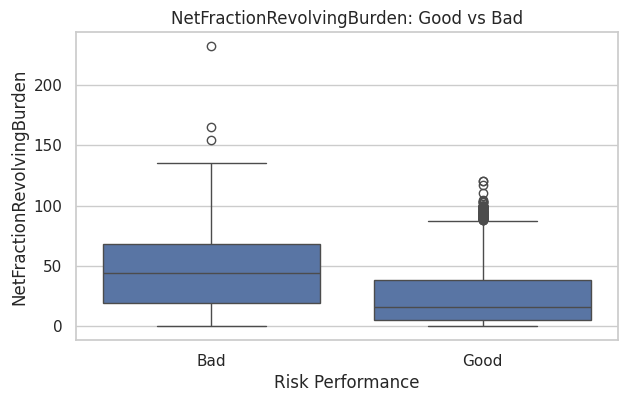

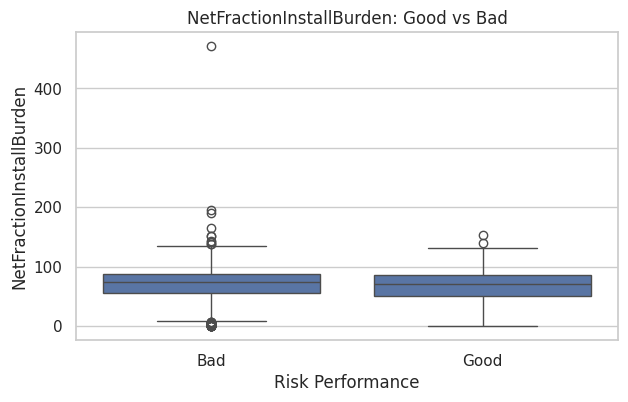

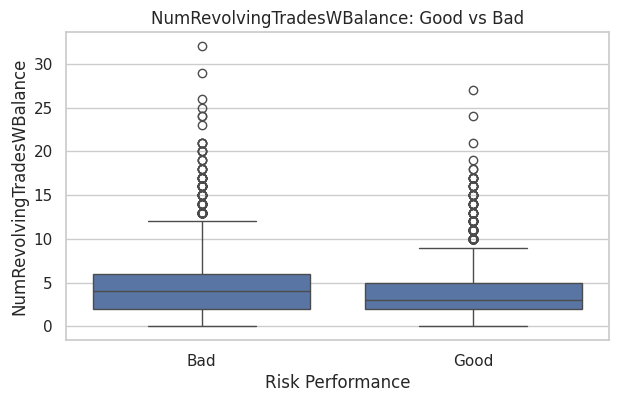

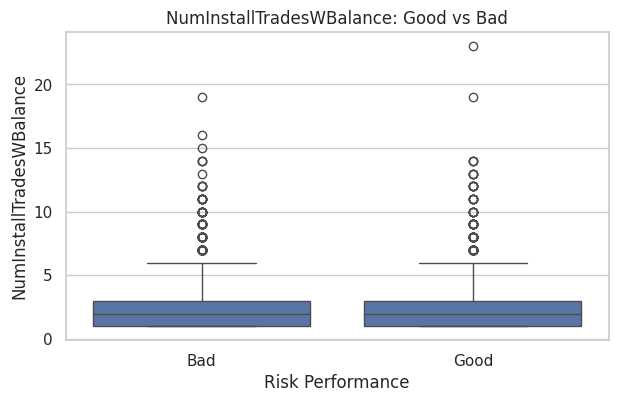

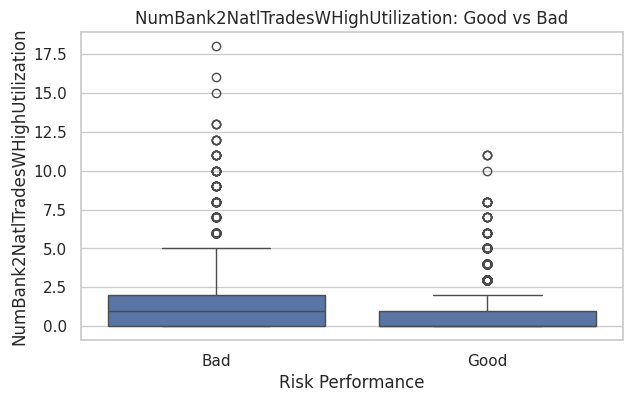

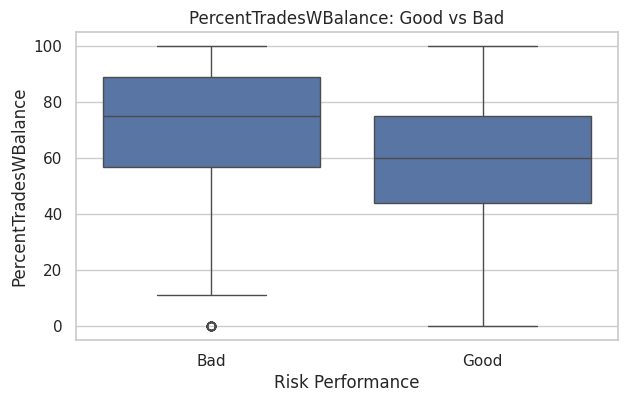

In [ ]:
#GOOD V/S BAD: NUMERIC FEATURE COMAPRISON
for col in feature_cols:

    plt.figure(figsize=(7,4))

    sns.boxplot(
        data=df_clean,
        x="RiskPerformance",
        y=col
    )

    plt.title(f"{col}: Good vs Bad")
    plt.xlabel("Risk Performance")
    plt.ylabel(col)

    plt.show()


In [ ]:
#GOOD VS BAD MEAN COMAPRISON
mean_comparison = (
    df_clean
    .groupby("RiskPerformance")[feature_cols]
    .mean()
    .T
)

mean_comparison

RiskPerformance,Bad,Good
ExternalRiskEstimate,67.695143,76.790830
MSinceOldestTradeOpen,180.419097,222.786595
MSinceMostRecentTradeOpen,9.009932,10.214150
AverageMInFile,70.791431,87.429989
NumSatisfactoryTrades,19.588510,22.785005
NumTrades60Ever2DerogPubRec,0.783057,0.362408
NumTrades90Ever2DerogPubRec,0.518793,0.239493
PercentTradesNeverDelq,89.459202,95.515312
MSinceMostRecentDelq,18.853674,27.051641
MaxDelq2PublicRecLast12M,5.384421,6.163464


In [ ]:
#MEDIAN COMPARISON
median_comparison = (
    df_clean
    .groupby("RiskPerformance")[feature_cols]
    .median()
    .T
)

median_comparison

RiskPerformance,Bad,Good
ExternalRiskEstimate,67.0,78.0
MSinceOldestTradeOpen,169.0,204.0
MSinceMostRecentTradeOpen,6.0,6.0
AverageMInFile,68.0,84.0
NumSatisfactoryTrades,18.0,21.0
NumTrades60Ever2DerogPubRec,0.0,0.0
NumTrades90Ever2DerogPubRec,0.0,0.0
PercentTradesNeverDelq,94.0,100.0
MSinceMostRecentDelq,12.0,22.0
MaxDelq2PublicRecLast12M,6.0,7.0


In [ ]:
#DIFFERENCE BETWEEN GOOD AND BAD
comparison = pd.DataFrame({
    "Good_Mean": df_clean[
        df_clean["RiskPerformance"] == "Good"
    ][feature_cols].mean(),

    "Bad_Mean": df_clean[
        df_clean["RiskPerformance"] == "Bad"
    ][feature_cols].mean()
})

comparison["Absolute_Difference"] = (
    comparison["Bad_Mean"] -
    comparison["Good_Mean"]
).abs()

comparison.sort_values(
    "Absolute_Difference",
    ascending=False
)

,Good_Mean,Bad_Mean,Absolute_Difference
MSinceOldestTradeOpen,222.786595,180.419097,42.367498
NetFractionRevolvingBurden,24.266709,44.838548,20.571839
AverageMInFile,87.429989,70.791431,16.638558
PercentTradesWBalance,60.043965,72.359695,12.315730
ExternalRiskEstimate,76.790830,67.695143,9.095687
MSinceMostRecentDelq,27.051641,18.853674,8.197967
PercentTradesNeverDelq,95.515312,89.459202,6.056110
PercentInstallTrades,31.993242,37.031938,5.038696
NetFractionInstallBurden,66.516262,70.210422,3.694160
NumSatisfactoryTrades,22.785005,19.588510,3.196495


In [ ]:
#BAD RATE ANALYSIS
df_eda = df_clean.copy()

df_eda["Bad_Flag"] = (
    df_eda["RiskPerformance"] == "Bad"
).astype(int)

print(df_eda["Bad_Flag"].value_counts())


Bad_Flag
1    5135
0    4735
Name: count, dtype: int64


In [ ]:
#BAD RATE BY ExternalRiskEstimate
df_eda["RiskEstimate_Bin"] = pd.qcut(
    df_eda["ExternalRiskEstimate"],
    q=5,
    duplicates="drop"
)

bad_rate_risk_estimate = (
    df_eda
    .groupby("RiskEstimate_Bin", observed=False)["Bad_Flag"]
    .mean() * 100
)

print(bad_rate_risk_estimate)

RiskEstimate_Bin
(32.999, 63.0]    81.910009
(63.0, 69.0]      68.118812
(69.0, 75.0]      51.880081
(75.0, 82.0]      32.597266
(82.0, 94.0]      18.191964
Name: Bad_Flag, dtype: float64


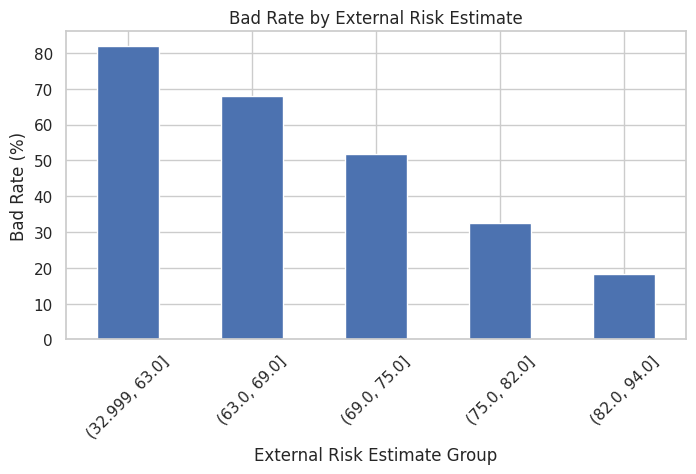

In [ ]:
bad_rate_risk_estimate.plot(
    kind="bar",
    figsize=(8,4)
)

plt.title("Bad Rate by External Risk Estimate")
plt.xlabel("External Risk Estimate Group")
plt.ylabel("Bad Rate (%)")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#BAD RATE FOR IMPORTANT VARIABLES
bad_rate_features = [
    "ExternalRiskEstimate",
    "PercentTradesNeverDelq",
    "NetFractionRevolvingBurden",
    "NetFractionInstallBurden",
    "NumInqLast6M",
    "NumInqLast6Mexcl7days",
    "NumTrades60Ever2DerogPubRec",
    "NumTrades90Ever2DerogPubRec",
    "NumTotalTrades",
    "NumRevolvingTradesWBalance",
    "NumInstallTradesWBalance"
]

In [ ]:
for col in bad_rate_features:

    temp = df_eda[[col, "Bad_Flag"]].copy()

    temp["Bin"] = pd.qcut(
        temp[col],
        q=5,
        duplicates="drop"
    )

    bad_rate = (
        temp
        .groupby("Bin", observed=False)["Bad_Flag"]
        .mean() * 100
    )

    print("\n" + "="*70)
    print(col)
    print("="*70)
    print(bad_rate)


ExternalRiskEstimate
Bin
(32.999, 63.0]    81.910009
(63.0, 69.0]      68.118812
(69.0, 75.0]      51.880081
(75.0, 82.0]      32.597266
(82.0, 94.0]      18.191964
Name: Bad_Flag, dtype: float64

PercentTradesNeverDelq
Bin
(-0.001, 86.0]    75.301205
(86.0, 95.0]      60.113587
(95.0, 100.0]     40.418680
Name: Bad_Flag, dtype: float64

NetFractionRevolvingBurden
Bin
(-0.001, 6.0]    29.975904
(6.0, 20.0]      36.936937
(20.0, 39.0]     49.973248
(39.0, 63.0]     63.779129
(63.0, 232.0]    78.445982
Name: Bad_Flag, dtype: float64

NetFractionInstallBurden
Bin
(-0.001, 48.0]    49.885233
(48.0, 67.0]      51.799100
(67.0, 79.0]      57.460317
(79.0, 90.0]      56.355283
(90.0, 471.0]     58.473896
Name: Bad_Flag, dtype: float64

NumInqLast6M
Bin
(-0.001, 1.0]    47.364353
(1.0, 2.0]       57.615894
(2.0, 66.0]      63.511370
Name: Bad_Flag, dtype: float64

NumInqLast6Mexcl7days
Bin
(-0.001, 1.0]    47.722113
(1.0, 2.0]       56.965517
(2.0, 66.0]      63.761721
Name: Bad_Flag, dtype: 

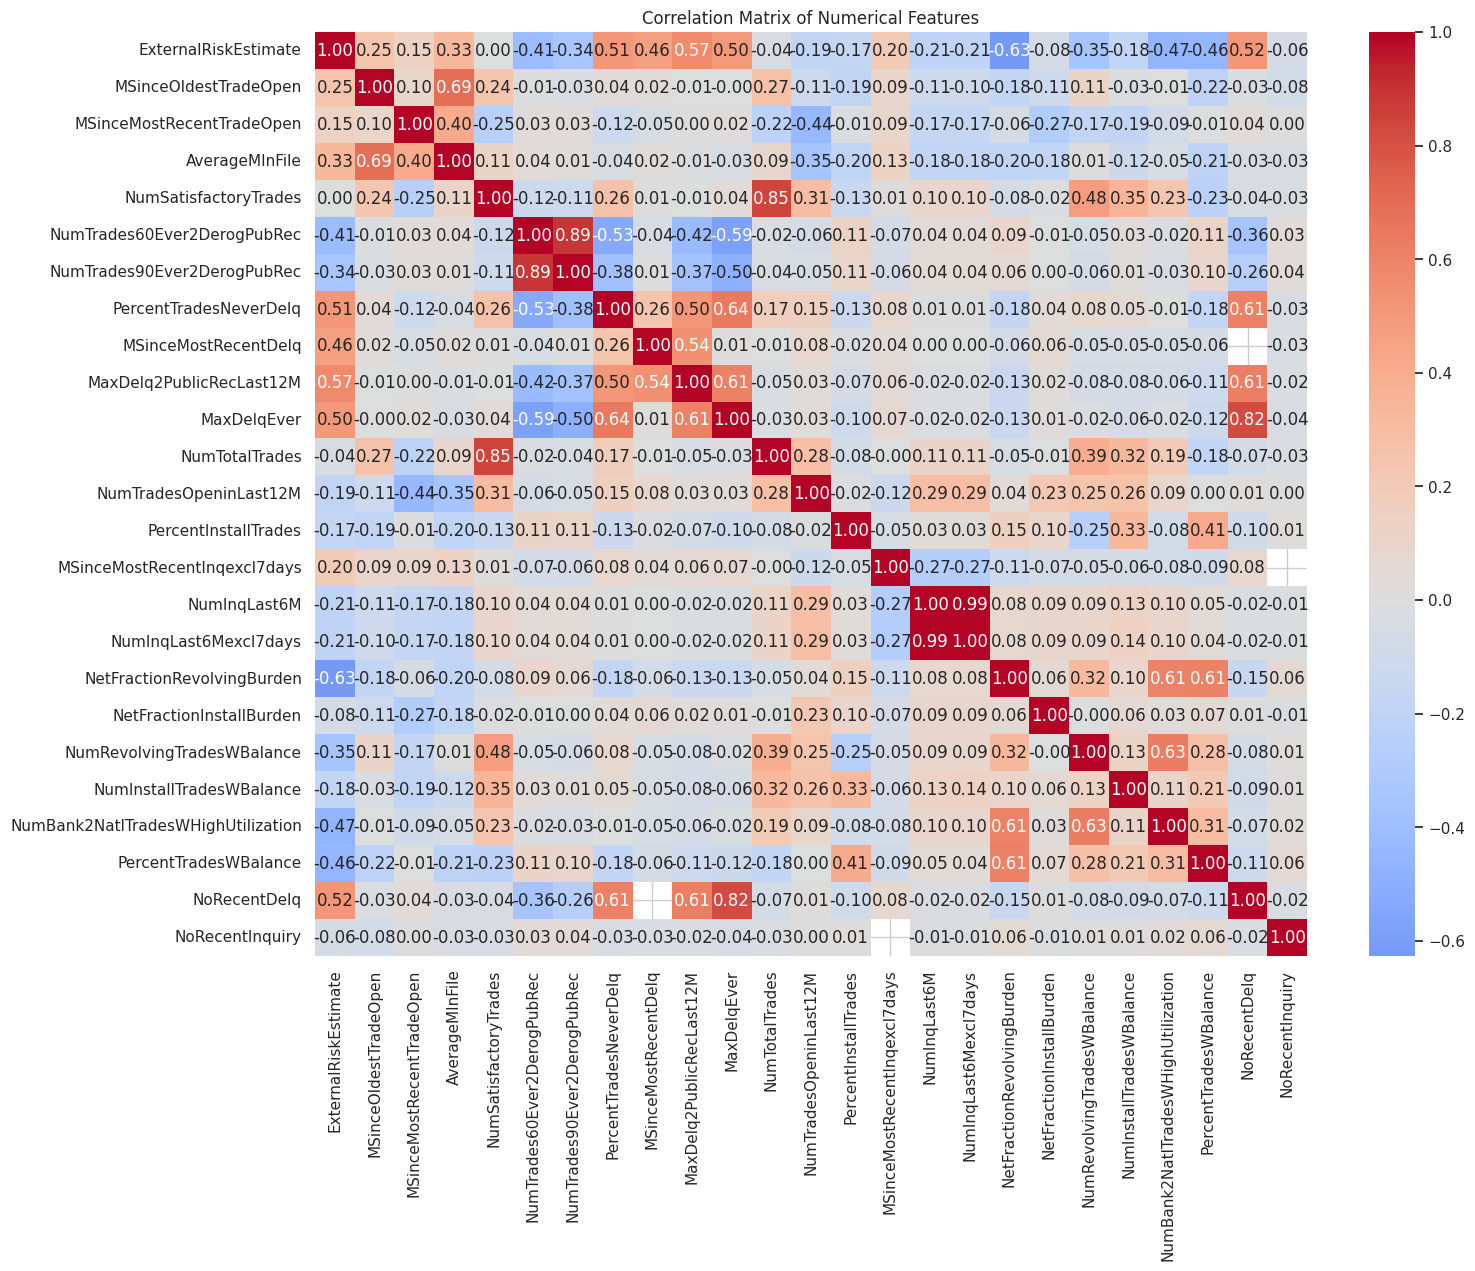

In [ ]:
#CORRELATION MATRIX
corr_matrix = df_clean[numeric_cols].corr()

plt.figure(figsize=(16,12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")

plt.show()

In [ ]:
#HIGHLY CORRELATED FEATURE PAIRS
corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

print(corr_pairs.head(20))

NumInqLast6M                 NumInqLast6Mexcl7days                 0.992204
NumTrades60Ever2DerogPubRec  NumTrades90Ever2DerogPubRec           0.890584
NumSatisfactoryTrades        NumTotalTrades                        0.845826
MaxDelqEver                  NoRecentDelq                          0.817469
MSinceOldestTradeOpen        AverageMInFile                        0.692120
PercentTradesNeverDelq       MaxDelqEver                           0.639176
NumRevolvingTradesWBalance   NumBank2NatlTradesWHighUtilization    0.627758
MaxDelq2PublicRecLast12M     NoRecentDelq                          0.613473
                             MaxDelqEver                           0.610661
PercentTradesNeverDelq       NoRecentDelq                          0.607730
NetFractionRevolvingBurden   PercentTradesWBalance                 0.606706
                             NumBank2NatlTradesWHighUtilization    0.605159
ExternalRiskEstimate         MaxDelq2PublicRecLast12M              0.568384
MSinceMostRe

In [ ]:
#STRONGEST NEGATIVE CORRELATION
print(corr_pairs.tail(20))

PercentInstallTrades          NumRevolvingTradesWBalance           -0.254310
NumTrades90Ever2DerogPubRec   NoRecentDelq                         -0.260459
MSinceMostRecentInqexcl7days  NumInqLast6Mexcl7days                -0.269633
                              NumInqLast6M                         -0.270081
MSinceMostRecentTradeOpen     NetFractionInstallBurden             -0.273569
ExternalRiskEstimate          NumTrades90Ever2DerogPubRec          -0.344171
                              NumRevolvingTradesWBalance           -0.347064
AverageMInFile                NumTradesOpeninLast12M               -0.352856
NumTrades60Ever2DerogPubRec   NoRecentDelq                         -0.358955
NumTrades90Ever2DerogPubRec   MaxDelq2PublicRecLast12M             -0.369935
                              PercentTradesNeverDelq               -0.381645
ExternalRiskEstimate          NumTrades60Ever2DerogPubRec          -0.412519
NumTrades60Ever2DerogPubRec   MaxDelq2PublicRecLast12M             -0.422764

In [ ]:
#TRATING BINARY FEATURES LIKE CONTINUOUS NUMERICAL VALUES
binary_features = [
    "NoRecentDelq",
    "NoRecentInquiry"
]

for col in binary_features:

    print("\n", col)

    print(
        df_clean[col]
        .value_counts()
    )

    print(
        df_clean[col]
        .value_counts(normalize=True) * 100
    )


 NoRecentDelq
NoRecentDelq
0    5206
1    4664
Name: count, dtype: int64
NoRecentDelq
0    52.745694
1    47.254306
Name: proportion, dtype: float64

 NoRecentInquiry
NoRecentInquiry
0    8015
1    1855
Name: count, dtype: int64
NoRecentInquiry
0    81.205674
1    18.794326
Name: proportion, dtype: float64


FIXING THE EXISTING MODEL

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

RANDOM_STATE = 42

In [ ]:
df_raw = df.copy()

print("Dataset shape:", df_raw.shape)
print(df_raw.head())

Dataset shape: (10459, 24)
  RiskPerformance  ExternalRiskEstimate  MSinceOldestTradeOpen  \
0             Bad                    55                    144   
1             Bad                    61                     58   
2             Bad                    67                     66   
3             Bad                    66                    169   
4             Bad                    81                    333   

   MSinceMostRecentTradeOpen  AverageMInFile  NumSatisfactoryTrades  \
0                          4              84                     20   
1                         15              41                      2   
2                          5              24                      9   
3                          1              73                     28   
4                         27             132                     12   

   NumTrades60Ever2DerogPubRec  NumTrades90Ever2DerogPubRec  \
0                            3                            0   
1                      

In [ ]:
TARGET_COL = "RiskPerformance"

target_mapping = {
    "Good": 0,
    "Bad": 1
}

df_raw["Target_Binary"] = df_raw[TARGET_COL].map(target_mapping)

print(df_raw["Target_Binary"].value_counts())
print(df_raw["Target_Binary"].value_counts(normalize=True))

Target_Binary
1    5459
0    5000
Name: count, dtype: int64
Target_Binary
1    0.521943
0    0.478057
Name: proportion, dtype: float64


In [ ]:
FEATURE_COLS = [
    col for col in df_raw.columns
    if col not in [TARGET_COL, "Target_Binary"]
]

print("Number of predictors:", len(FEATURE_COLS))
print(FEATURE_COLS)

Number of predictors: 23
['ExternalRiskEstimate', 'MSinceOldestTradeOpen', 'MSinceMostRecentTradeOpen', 'AverageMInFile', 'NumSatisfactoryTrades', 'NumTrades60Ever2DerogPubRec', 'NumTrades90Ever2DerogPubRec', 'PercentTradesNeverDelq', 'MSinceMostRecentDelq', 'MaxDelq2PublicRecLast12M', 'MaxDelqEver', 'NumTotalTrades', 'NumTradesOpeninLast12M', 'PercentInstallTrades', 'MSinceMostRecentInqexcl7days', 'NumInqLast6M', 'NumInqLast6Mexcl7days', 'NetFractionRevolvingBurden', 'NetFractionInstallBurden', 'NumRevolvingTradesWBalance', 'NumInstallTradesWBalance', 'NumBank2NatlTradesWHighUtilization', 'PercentTradesWBalance']


In [ ]:
no_hit_mask = df_raw[FEATURE_COLS].eq(-9).all(axis=1)

print("No-hit applicants:", no_hit_mask.sum())
print("Bureau-hit applicants:", (~no_hit_mask).sum())

No-hit applicants: 588
Bureau-hit applicants: 9871


In [ ]:
df_no_hit = df_raw.loc[no_hit_mask].copy()

df_model = df_raw.loc[~no_hit_mask].copy()

print("No-hit dataset shape:", df_no_hit.shape)
print("Modeling dataset shape:", df_model.shape)

No-hit dataset shape: (588, 25)
Modeling dataset shape: (9871, 25)


In [ ]:
print("No-hit applicant target distribution:")
print(
    df_no_hit["Target_Binary"]
    .value_counts()
    .rename(index={0: "Good", 1: "Bad"})
)

print("\nNo-hit applicant default rate:")
print(df_no_hit["Target_Binary"].mean())

No-hit applicant target distribution:
Target_Binary
Bad     323
Good    265
Name: count, dtype: int64

No-hit applicant default rate:
0.5493197278911565


In [ ]:
df_clean = df_model.copy()

FLAG_COLS = []

for col in FEATURE_COLS:

    # Create -7 flag only if -7 exists
    if (df_clean[col] == -7).any():
        flag_col = f"{col}_minus7_flag"
        df_clean[flag_col] = (df_clean[col] == -7).astype(int)
        FLAG_COLS.append(flag_col)

    # Create -8 flag only if -8 exists
    if (df_clean[col] == -8).any():
        flag_col = f"{col}_minus8_flag"
        df_clean[flag_col] = (df_clean[col] == -8).astype(int)
        FLAG_COLS.append(flag_col)

    # Create -9 flag only if -9 exists
    if (df_clean[col] == -9).any():
        flag_col = f"{col}_minus9_flag"
        df_clean[flag_col] = (df_clean[col] == -9).astype(int)
        FLAG_COLS.append(flag_col)

    # Convert special values to NaN
    df_clean[col] = df_clean[col].replace({
        -7: np.nan,
        -8: np.nan,
        -9: np.nan
    })

print("Original features:", len(FEATURE_COLS))
print("Special-value flags:", len(FLAG_COLS))

Original features: 23
Special-value flags: 12


In [ ]:
print(df_clean[FEATURE_COLS].isna().sum().sort_values(ascending=False).head(10))

MSinceMostRecentDelq                  4840
NetFractionInstallBurden              3419
MSinceMostRecentInqexcl7days          2331
NumInstallTradesWBalance               861
NumBank2NatlTradesWHighUtilization     583
MSinceOldestTradeOpen                  239
NetFractionRevolvingBurden             186
NumRevolvingTradesWBalance             156
PercentTradesWBalance                   18
ExternalRiskEstimate                    10
dtype: int64


In [ ]:
FLAG_COLS = [
    col for col in df_clean.columns
    if col.endswith("_flag")
]

MODEL_FEATURES = FEATURE_COLS + FLAG_COLS

print("Original features:", len(FEATURE_COLS))
print("Flag features:", len(FLAG_COLS))
print("Total modeling features:", len(MODEL_FEATURES))

Original features: 23
Flag features: 12
Total modeling features: 35


In [ ]:
X = df_clean[MODEL_FEATURES].copy()

y = df_clean["Target_Binary"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (9871, 35)
y shape: (9871,)

Target distribution:
Target_Binary
1    5136
0    4735
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (7896, 35)
Test set: (1975, 35)

Training target distribution:
Target_Binary
1    0.520263
0    0.479737
Name: proportion, dtype: float64

Test target distribution:
Target_Binary
1    0.520506
0    0.479494
Name: proportion, dtype: float64


In [ ]:
lr_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

In [ ]:
lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

In [ ]:
xgb_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

In [ ]:
xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.8, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [ ]:
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]

xgb_prob = xgb_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
def evaluate_model(model_name, y_true, probabilities, threshold=0.5):

    predictions = (probabilities >= threshold).astype(int)

    auc = roc_auc_score(y_true, probabilities)
    pr_auc = average_precision_score(y_true, probabilities)
    brier = brier_score_loss(y_true, probabilities)

    accuracy = accuracy_score(y_true, predictions)
    precision = precision_score(y_true, predictions, zero_division=0)
    recall = recall_score(y_true, predictions, zero_division=0)
    f1 = f1_score(y_true, predictions, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    gini = 2 * auc - 1

    return {
        "Model": model_name,
        "ROC-AUC": auc,
        "PR-AUC": pr_auc,
        "Gini": gini,
        "Brier Score": brier,
        "Accuracy": accuracy,
        "Precision (Bad)": precision,
        "Recall (Bad)": recall,
        "F1 (Bad)": f1,
        "Specificity": specificity
    }

In [ ]:
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_prob
)

lr_results

{'Model': 'Logistic Regression',
 'ROC-AUC': np.float64(0.8086564576237061),
 'PR-AUC': np.float64(0.8103902793200655),
 'Gini': np.float64(0.6173129152474122),
 'Brier Score': np.float64(0.17829309815383365),
 'Accuracy': 0.7382278481012658,
 'Precision (Bad)': 0.7390084190832554,
 'Recall (Bad)': 0.7684824902723736,
 'F1 (Bad)': 0.7534573199809251,
 'Specificity': np.float64(0.7053854276663146)}

In [ ]:
xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    xgb_prob
)

xgb_results

{'Model': 'XGBoost',
 'ROC-AUC': np.float64(0.8077175927257487),
 'PR-AUC': np.float64(0.8132263129390482),
 'Gini': np.float64(0.6154351854514974),
 'Brier Score': np.float64(0.17839711732144495),
 'Accuracy': 0.7326582278481013,
 'Precision (Bad)': 0.7340823970037453,
 'Recall (Bad)': 0.7626459143968871,
 'F1 (Bad)': 0.7480916030534351,
 'Specificity': np.float64(0.7001055966209081)}

In [ ]:
baseline_results = pd.DataFrame([
    lr_results,
    xgb_results
])

baseline_results

,Model,ROC-AUC,PR-AUC,Gini,Brier Score,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),Specificity
0,Logistic Regression,0.808656,0.810390,0.617313,0.178293,0.738228,0.739008,0.768482,0.753457,0.705385
1,XGBoost,0.807718,0.813226,0.615435,0.178397,0.732658,0.734082,0.762646,0.748092,0.700106


In [ ]:
baseline_results.round(4)

,Model,ROC-AUC,PR-AUC,Gini,Brier Score,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),Specificity
0,Logistic Regression,0.8087,0.8104,0.6173,0.1783,0.7382,0.7390,0.7685,0.7535,0.7054
1,XGBoost,0.8077,0.8132,0.6154,0.1784,0.7327,0.7341,0.7626,0.7481,0.7001


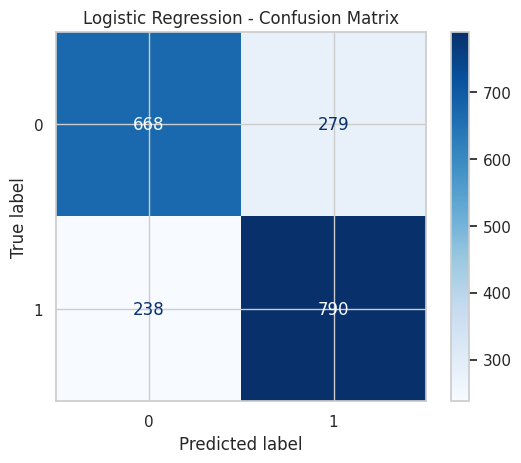

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    (lr_prob >= 0.5).astype(int),
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

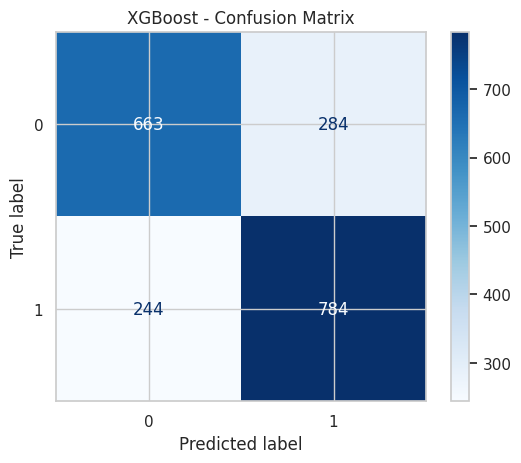

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (xgb_prob >= 0.5).astype(int),
    cmap="Blues"
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

<Figure size 800x600 with 0 Axes>

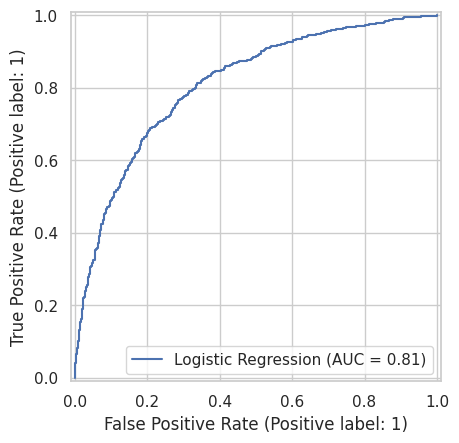

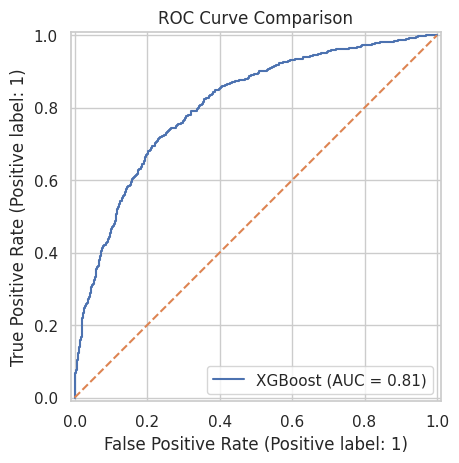

In [ ]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_prob,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    xgb_prob,
    name="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve Comparison")
plt.show()

In [ ]:
lr_train_prob = lr_pipeline.predict_proba(X_train)[:, 1]
xgb_train_prob = xgb_pipeline.predict_proba(X_train)[:, 1]

train_test_auc = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "XGBoost"
    ],
    "Train ROC-AUC": [
        roc_auc_score(y_train, lr_train_prob),
        roc_auc_score(y_train, xgb_train_prob)
    ],
    "Test ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, xgb_prob)
    ]
})

train_test_auc["AUC Gap"] = (
    train_test_auc["Train ROC-AUC"]
    - train_test_auc["Test ROC-AUC"]
)

train_test_auc.round(4)

,Model,Train ROC-AUC,Test ROC-AUC,AUC Gap
0,Logistic Regression,0.8089,0.8087,0.0003
1,XGBoost,0.8528,0.8077,0.0451


In [ ]:
baseline_results.to_csv(
    "baseline_model_comparison.csv",
    index=False
)

print("Baseline comparison table saved.")

Baseline comparison table saved.


FIXING THE EXISTING MODEL

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42

In [ ]:
df_raw = df.copy()

print("Dataset shape:", df_raw.shape)
print(df_raw.head())

Dataset shape: (10459, 24)
  RiskPerformance  ExternalRiskEstimate  MSinceOldestTradeOpen  \
0             Bad                    55                    144   
1             Bad                    61                     58   
2             Bad                    67                     66   
3             Bad                    66                    169   
4             Bad                    81                    333   

   MSinceMostRecentTradeOpen  AverageMInFile  NumSatisfactoryTrades  \
0                          4              84                     20   
1                         15              41                      2   
2                          5              24                      9   
3                          1              73                     28   
4                         27             132                     12   

   NumTrades60Ever2DerogPubRec  NumTrades90Ever2DerogPubRec  \
0                            3                            0   
1                      

In [ ]:
TARGET_COL = "RiskPerformance"

target_mapping = {
    "Good": 0,
    "Bad": 1
}

df_raw["Target_Binary"] = df_raw[TARGET_COL].map(target_mapping)

print("Target distribution:")
print(df_raw["Target_Binary"].value_counts())

print("\nTarget distribution (%):")
print(
    df_raw["Target_Binary"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target distribution:
Target_Binary
1    5459
0    5000
Name: count, dtype: int64

Target distribution (%):
Target_Binary
1    52.19
0    47.81
Name: proportion, dtype: float64


In [ ]:
FEATURE_COLS = [
    col for col in df_raw.columns
    if col not in [TARGET_COL, "Target_Binary"]
]

print("Number of predictors:", len(FEATURE_COLS))
print(FEATURE_COLS)

Number of predictors: 23
['ExternalRiskEstimate', 'MSinceOldestTradeOpen', 'MSinceMostRecentTradeOpen', 'AverageMInFile', 'NumSatisfactoryTrades', 'NumTrades60Ever2DerogPubRec', 'NumTrades90Ever2DerogPubRec', 'PercentTradesNeverDelq', 'MSinceMostRecentDelq', 'MaxDelq2PublicRecLast12M', 'MaxDelqEver', 'NumTotalTrades', 'NumTradesOpeninLast12M', 'PercentInstallTrades', 'MSinceMostRecentInqexcl7days', 'NumInqLast6M', 'NumInqLast6Mexcl7days', 'NetFractionRevolvingBurden', 'NetFractionInstallBurden', 'NumRevolvingTradesWBalance', 'NumInstallTradesWBalance', 'NumBank2NatlTradesWHighUtilization', 'PercentTradesWBalance']


In [ ]:
no_hit_mask = df_raw[FEATURE_COLS].eq(-9).all(axis=1)

print("No-hit applicants:", no_hit_mask.sum())
print("Bureau-hit applicants:", (~no_hit_mask).sum())

No-hit applicants: 588
Bureau-hit applicants: 9871


In [ ]:
df_no_hit = df_raw.loc[no_hit_mask].copy()

df_model = df_raw.loc[~no_hit_mask].copy()

print("No-hit dataset shape:", df_no_hit.shape)
print("Modeling dataset shape:", df_model.shape)

No-hit dataset shape: (588, 25)
Modeling dataset shape: (9871, 25)


In [ ]:
print("No-hit applicant target distribution:")

print(
    df_no_hit["Target_Binary"]
    .value_counts()
    .rename(index={
        0: "Good",
        1: "Bad"
    })
)

print("\nNo-hit applicant default rate:")
print(
    round(df_no_hit["Target_Binary"].mean(), 4)
)

No-hit applicant target distribution:
Target_Binary
Bad     323
Good    265
Name: count, dtype: int64

No-hit applicant default rate:
0.5493


In [ ]:
df_clean = df_model.copy()

FLAG_COLS = []

for col in FEATURE_COLS:

    # Create -7 flag only if -7 exists
    if (df_clean[col] == -7).any():
        flag_col = f"{col}_minus7_flag"
        df_clean[flag_col] = (
            df_clean[col] == -7
        ).astype(int)
        FLAG_COLS.append(flag_col)

    # Create -8 flag only if -8 exists
    if (df_clean[col] == -8).any():
        flag_col = f"{col}_minus8_flag"
        df_clean[flag_col] = (
            df_clean[col] == -8
        ).astype(int)
        FLAG_COLS.append(flag_col)

    # Create isolated -9 flag only if -9 exists
    if (df_clean[col] == -9).any():
        flag_col = f"{col}_minus9_flag"
        df_clean[flag_col] = (
            df_clean[col] == -9
        ).astype(int)
        FLAG_COLS.append(flag_col)

    # Convert special values to NaN
    df_clean[col] = df_clean[col].replace({
        -7: np.nan,
        -8: np.nan,
        -9: np.nan
    })

print("Original features:", len(FEATURE_COLS))
print("Special-value flags:", len(FLAG_COLS))

Original features: 23
Special-value flags: 12


In [ ]:
print("Remaining special values in original features:\n")

for value in [-7, -8, -9]:
    count = (
        df_clean[FEATURE_COLS] == value
    ).sum().sum()

    print(f"{value}: {count}")

Remaining special values in original features:

-7: 0
-8: 0
-9: 0


In [ ]:
print("\nTotal missing values after conversion:")
print(
    df_clean[FEATURE_COLS]
    .isna()
    .sum()
    .sum()
)


Total missing values after conversion:
12643


In [ ]:
MODEL_FEATURES = FEATURE_COLS + FLAG_COLS

print("Original features:", len(FEATURE_COLS))
print("Special-value flags:", len(FLAG_COLS))
print("Total modeling features:", len(MODEL_FEATURES))

Original features: 23
Special-value flags: 12
Total modeling features: 35


In [ ]:
X = df_clean[MODEL_FEATURES].copy()

y = df_clean["Target_Binary"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(
    y.value_counts()
    .rename(index={
        0: "Good",
        1: "Bad"
    })
)

X shape: (9871, 35)
y shape: (9871,)

Target distribution:
Target_Binary
Bad     5136
Good    4735
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(
    y_train
    .value_counts(normalize=True)
    .rename(index={
        0: "Good",
        1: "Bad"
    })
)

print("\nTest target distribution:")
print(
    y_test
    .value_counts(normalize=True)
    .rename(index={
        0: "Good",
        1: "Bad"
    })
)

Training set: (7896, 35)
Test set: (1975, 35)

Training target distribution:
Target_Binary
Bad     0.520263
Good    0.479737
Name: proportion, dtype: float64

Test target distribution:
Target_Binary
Bad     0.520506
Good    0.479494
Name: proportion, dtype: float64


In [ ]:
lr_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

In [ ]:
lr_pipeline.fit(
    X_train,
    y_train
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [ ]:
xgb_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

In [ ]:
xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost trained successfully.")

XGBoost trained successfully.


In [ ]:
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]

xgb_prob = xgb_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression probability range:")
print(lr_prob.min(), "to", lr_prob.max())

print("\nXGBoost probability range:")
print(xgb_prob.min(), "to", xgb_prob.max())

Logistic Regression probability range:
0.027433207244239696 to 0.9871446399748066

XGBoost probability range:
0.048610296 to 0.9636364


In [ ]:
def evaluate_model(
    model_name,
    y_true,
    probabilities,
    threshold=0.5
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    auc = roc_auc_score(
        y_true,
        probabilities
    )

    pr_auc = average_precision_score(
        y_true,
        probabilities
    )

    brier = brier_score_loss(
        y_true,
        probabilities
    )

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions
    ).ravel()

    sensitivity = tp / (tp + fn)

    specificity = tn / (tn + fp)

    gini = 2 * auc - 1

    return {
        "Model": model_name,
        "ROC-AUC": auc,
        "PR-AUC": pr_auc,
        "Gini": gini,
        "Brier Score": brier,
        "Accuracy": accuracy,
        "Precision (Bad)": precision,
        "Recall (Bad)": recall,
        "F1 (Bad)": f1,
        "Specificity": specificity
    }

In [ ]:
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_prob
)

lr_results

{'Model': 'Logistic Regression',
 'ROC-AUC': np.float64(0.8086564576237061),
 'PR-AUC': np.float64(0.8103902793200655),
 'Gini': np.float64(0.6173129152474122),
 'Brier Score': np.float64(0.17829309815383365),
 'Accuracy': 0.7382278481012658,
 'Precision (Bad)': 0.7390084190832554,
 'Recall (Bad)': 0.7684824902723736,
 'F1 (Bad)': 0.7534573199809251,
 'Specificity': np.float64(0.7053854276663146)}

In [ ]:
xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    xgb_prob
)

xgb_results

{'Model': 'XGBoost',
 'ROC-AUC': np.float64(0.8077175927257487),
 'PR-AUC': np.float64(0.8132263129390482),
 'Gini': np.float64(0.6154351854514974),
 'Brier Score': np.float64(0.17839711732144495),
 'Accuracy': 0.7326582278481013,
 'Precision (Bad)': 0.7340823970037453,
 'Recall (Bad)': 0.7626459143968871,
 'F1 (Bad)': 0.7480916030534351,
 'Specificity': np.float64(0.7001055966209081)}

In [ ]:
baseline_results = pd.DataFrame([
    lr_results,
    xgb_results
])

baseline_results.round(4)

,Model,ROC-AUC,PR-AUC,Gini,Brier Score,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),Specificity
0,Logistic Regression,0.8087,0.8104,0.6173,0.1783,0.7382,0.7390,0.7685,0.7535,0.7054
1,XGBoost,0.8077,0.8132,0.6154,0.1784,0.7327,0.7341,0.7626,0.7481,0.7001


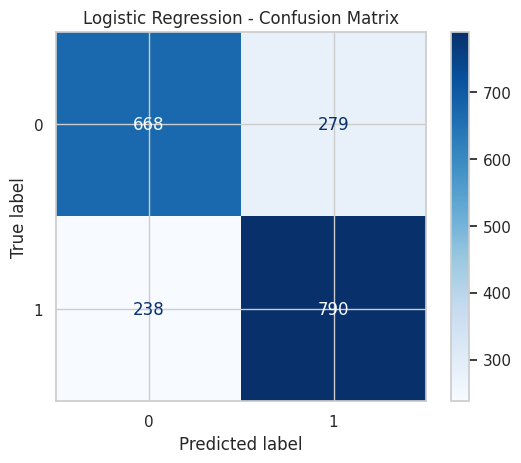

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (lr_prob >= 0.5).astype(int),
    cmap="Blues"
)

plt.title(
    "Logistic Regression - Confusion Matrix"
)

plt.show()

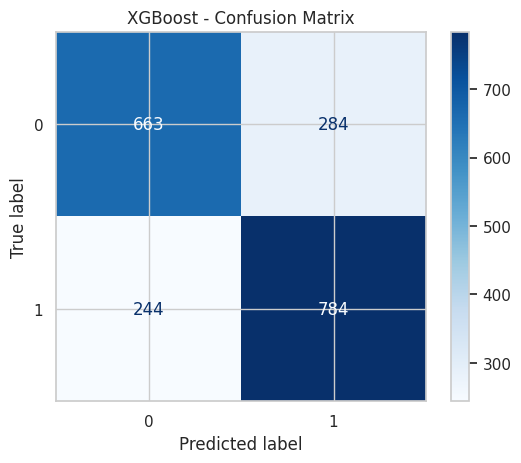

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (xgb_prob >= 0.5).astype(int),
    cmap="Blues"
)

plt.title(
    "XGBoost - Confusion Matrix"
)

plt.show()

<Figure size 800x600 with 0 Axes>

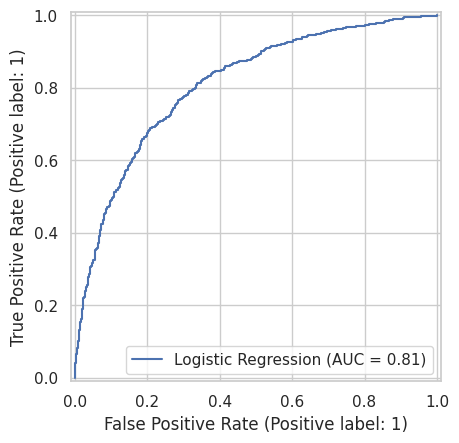

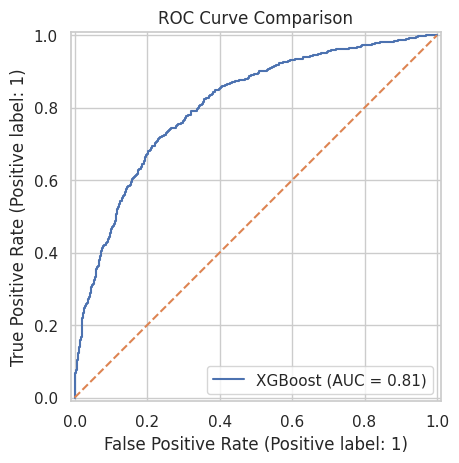

In [ ]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_prob,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    xgb_prob,
    name="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title(
    "ROC Curve Comparison"
)

plt.show()

<Figure size 800x600 with 0 Axes>

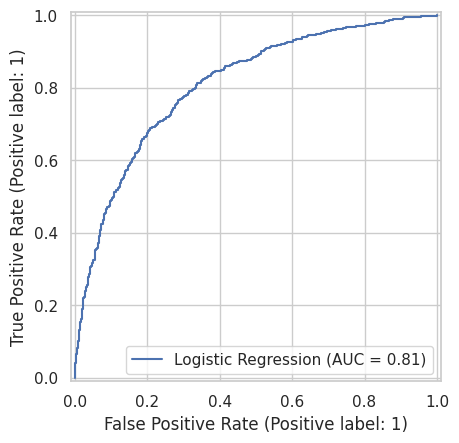

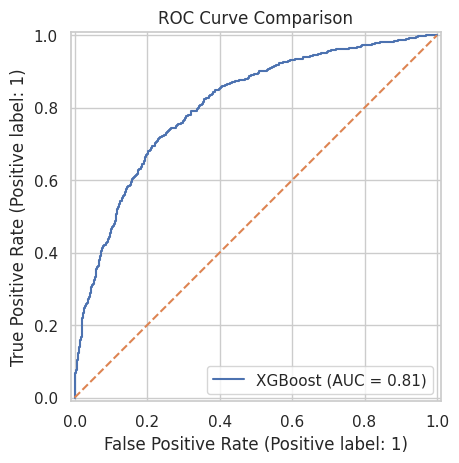

In [ ]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_prob,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    xgb_prob,
    name="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title(
    "ROC Curve Comparison"
)

plt.show()

In [ ]:
lr_train_prob = (
    lr_pipeline
    .predict_proba(X_train)[:, 1]
)

xgb_train_prob = (
    xgb_pipeline
    .predict_proba(X_train)[:, 1]
)

train_test_auc = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "XGBoost"
    ],

    "Train ROC-AUC": [
        roc_auc_score(
            y_train,
            lr_train_prob
        ),
        roc_auc_score(
            y_train,
            xgb_train_prob
        )
    ],

    "Test ROC-AUC": [
        roc_auc_score(
            y_test,
            lr_prob
        ),
        roc_auc_score(
            y_test,
            xgb_prob
        )
    ]
})

train_test_auc["AUC Gap"] = (
    train_test_auc["Train ROC-AUC"]
    - train_test_auc["Test ROC-AUC"]
)

train_test_auc.round(4)

,Model,Train ROC-AUC,Test ROC-AUC,AUC Gap
0,Logistic Regression,0.8089,0.8087,0.0003
1,XGBoost,0.8528,0.8077,0.0451


In [ ]:
baseline_results.to_csv(
    "baseline_model_comparison.csv",
    index=False
)

print(
    "Baseline comparison table saved successfully."
)

Baseline comparison table saved successfully.


TRADITIONAL CREDIT SCORECARD


In [ ]:
# ============================================================
# STEP 2 — TRADITIONAL CREDIT SCORECARD
# Manual WOE + IV + Logistic Regression
# ============================================================

import numpy as np
import pandas as pd

print("Preparing scorecard dataset...")

# Use the original 23 variables
X_scorecard = df_model[FEATURE_COLS].copy()
y_scorecard = y.copy()

print("Scorecard population:", X_scorecard.shape)
print("Number of variables:", len(FEATURE_COLS))

Preparing scorecard dataset...
Scorecard population: (9871, 23)
Number of variables: 23


In [ ]:
# ============================================================
# USE SAME TRAIN / TEST SPLIT AS BASELINE
# ============================================================

X_train_sc = X_scorecard.loc[X_train.index].copy()
X_test_sc = X_scorecard.loc[X_test.index].copy()

y_train_sc = y.loc[X_train.index].copy()
y_test_sc = y.loc[X_test.index].copy()

print("Training data:", X_train_sc.shape)
print("Test data:", X_test_sc.shape)

print("\nTraining Bad rate:", y_train_sc.mean())
print("Test Bad rate:", y_test_sc.mean())

Training data: (7896, 23)
Test data: (1975, 23)

Training Bad rate: 0.5202634245187436
Test Bad rate: 0.520506329113924


In [ ]:
# ============================================================
# WEIGHT OF EVIDENCE FUNCTION
# ============================================================

def calculate_woe(train_x, train_y, test_x=None, n_bins=5):

    train_temp = pd.DataFrame({
        "feature": train_x,
        "target": train_y
    })

    # Store original special codes
    special_codes = [-9, -8, -7]

    # Separate special values
    train_temp["is_special"] = train_temp["feature"].isin(special_codes)

    normal_data = train_temp.loc[
        ~train_temp["is_special"], "feature"
    ].dropna()

    # Create quantile bins only using training data
    if normal_data.nunique() >= 2:
        try:
            _, bin_edges = pd.qcut(
                normal_data,
                q=n_bins,
                retbins=True,
                duplicates="drop"
            )

            bin_edges[0] = -np.inf
            bin_edges[-1] = np.inf

        except:
            bin_edges = [-np.inf, np.inf]

    else:
        bin_edges = [-np.inf, np.inf]

    # Assign bins
    def assign_bins(series):

        result = pd.Series(index=series.index, dtype="object")

        # Special values
        result[series == -9] = "SPECIAL_-9"
        result[series == -8] = "SPECIAL_-8"
        result[series == -7] = "SPECIAL_-7"

        # Missing
        result[series.isna()] = "MISSING"

        # Normal values
        mask = ~series.isin(special_codes) & series.notna()

        if len(bin_edges) > 2:
            result.loc[mask] = pd.cut(
                series.loc[mask],
                bins=bin_edges,
                include_lowest=True
            ).astype(str)
        else:
            result.loc[mask] = "NORMAL"

        return result

    train_bins = assign_bins(train_x)

    # Create WOE table
    temp = pd.DataFrame({
        "bin": train_bins,
        "target": train_y
    })

    grouped = temp.groupby("bin", observed=False)["target"].agg(
        ["count", "sum"]
    )

    grouped["bad"] = grouped["sum"]
    grouped["good"] = grouped["count"] - grouped["bad"]

    total_bad = grouped["bad"].sum()
    total_good = grouped["good"].sum()

    # Smoothing to avoid division by zero
    grouped["dist_bad"] = (
        grouped["bad"] + 0.5
    ) / (total_bad + 0.5 * len(grouped))

    grouped["dist_good"] = (
        grouped["good"] + 0.5
    ) / (total_good + 0.5 * len(grouped))

    grouped["woe"] = np.log(
        grouped["dist_good"] / grouped["dist_bad"]
    )

    grouped["iv"] = (
        grouped["dist_good"] - grouped["dist_bad"]
    ) * grouped["woe"]

    woe_mapping = grouped["woe"].to_dict()

    # Transform training data
    train_woe = train_bins.map(woe_mapping)

    # Transform test data using TRAINING bins only
    if test_x is not None:
        test_bins = assign_bins(test_x)
        test_woe = test_bins.map(woe_mapping)

        # Unknown bins → 0 WOE
        test_woe = test_woe.fillna(0)

    else:
        test_woe = None

    total_iv = grouped["iv"].sum()

    return train_woe, test_woe, total_iv, grouped

In [ ]:
# ============================================================
# TEST WOE ON ONE VARIABLE
# ============================================================

test_feature = "ExternalRiskEstimate"

train_woe_test, test_woe_test, iv_test, woe_table_test = calculate_woe(
    X_train_sc[test_feature],
    y_train_sc,
    X_test_sc[test_feature]
)

print("Feature:", test_feature)
print("IV:", round(iv_test, 4))

display(woe_table_test)

Feature: ExternalRiskEstimate
IV: 0.9677


,count,sum,bad,good,dist_bad,dist_good,woe,iv
bin,,,,,,,,
"(-inf, 63.0]",1748,1427,1427,321,0.347239,0.084806,-1.409646,0.369938
"(63.0, 69.0]",1619,1099,1099,520,0.267453,0.137299,-0.666784,0.086785
"(69.0, 75.0]",1559,810,810,749,0.197154,0.197705,0.002791,0.000002
"(75.0, 82.0]",1527,508,508,1019,0.123693,0.268926,0.776639,0.112794
"(82.0, inf]",1434,257,257,1177,0.062637,0.310604,1.601166,0.397037
SPECIAL_-9,9,7,7,2,0.001824,0.000659,-1.017576,0.001185


In [ ]:
# ============================================================
# APPLY WOE TO ALL FEATURES
# ============================================================

X_train_woe = pd.DataFrame(index=X_train_sc.index)
X_test_woe = pd.DataFrame(index=X_test_sc.index)

iv_results = []

for feature in FEATURE_COLS:

    train_woe, test_woe, iv_value, _ = calculate_woe(
        X_train_sc[feature],
        y_train_sc,
        X_test_sc[feature],
        n_bins=5
    )

    X_train_woe[feature] = train_woe
    X_test_woe[feature] = test_woe

    iv_results.append({
        "Feature": feature,
        "IV": iv_value
    })

iv_table = pd.DataFrame(iv_results).sort_values(
    "IV",
    ascending=False
)

print("WOE transformation completed.")
print("\nTop variables by IV:")

display(iv_table)

WOE transformation completed.

Top variables by IV:


,Feature,IV
0,ExternalRiskEstimate,0.967740
17,NetFractionRevolvingBurden,0.546563
7,PercentTradesNeverDelq,0.364149
22,PercentTradesWBalance,0.344363
9,MaxDelq2PublicRecLast12M,0.324774
8,MSinceMostRecentDelq,0.317673
3,AverageMInFile,0.298944
21,NumBank2NatlTradesWHighUtilization,0.253028
10,MaxDelqEver,0.241776
14,MSinceMostRecentInqexcl7days,0.222056


In [ ]:
# ============================================================
# IV-BASED VARIABLE SELECTION
# ============================================================

selected_features = iv_table.loc[
    (iv_table["IV"] >= 0.02) &
    (iv_table["IV"] <= 1.0),
    "Feature"
].tolist()

print("Variables selected:", len(selected_features))

print("\nSelected variables:")
for feature in selected_features:
    print("-", feature)

Variables selected: 22

Selected variables:
- ExternalRiskEstimate
- NetFractionRevolvingBurden
- PercentTradesNeverDelq
- PercentTradesWBalance
- MaxDelq2PublicRecLast12M
- MSinceMostRecentDelq
- AverageMInFile
- NumBank2NatlTradesWHighUtilization
- MaxDelqEver
- MSinceMostRecentInqexcl7days
- MSinceOldestTradeOpen
- NumRevolvingTradesWBalance
- NumTrades60Ever2DerogPubRec
- PercentInstallTrades
- NumSatisfactoryTrades
- NumInqLast6M
- NumTrades90Ever2DerogPubRec
- NumInqLast6Mexcl7days
- NumTotalTrades
- NetFractionInstallBurden
- NumInstallTradesWBalance
- NumTradesOpeninLast12M


In [ ]:
# ============================================================
# WOE + LOGISTIC REGRESSION SCORECARD MODEL
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

scorecard_lr = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

scorecard_lr.fit(
    X_train_woe[selected_features],
    y_train_sc
)

scorecard_train_prob = scorecard_lr.predict_proba(
    X_train_woe[selected_features]
)[:, 1]

scorecard_test_prob = scorecard_lr.predict_proba(
    X_test_woe[selected_features]
)[:, 1]

print("Scorecard Logistic Regression trained.")

print(
    "\nTrain ROC-AUC:",
    round(
        roc_auc_score(y_train_sc, scorecard_train_prob),
        4
    )
)

print(
    "Test ROC-AUC:",
    round(
        roc_auc_score(y_test_sc, scorecard_test_prob),
        4
    )
)

Scorecard Logistic Regression trained.

Train ROC-AUC: 0.805
Test ROC-AUC: 0.8029


In [ ]:
# ============================================================
# CONVERT SCORECARD MODEL INTO CREDIT SCORE
# ============================================================

BASE_SCORE = 600
BASE_ODDS = 30
PDO = 20

# Calculate odds from predicted probability
# Probability = P(Bad)
# Good probability = 1 - P(Bad)

def probability_to_score(pd_value):
    """
    Convert probability of default into a credit score.

    Base score = 600
    Base odds = 30:1 Good:Bad
    PDO = 20
    """

    pd_value = np.clip(pd_value, 0.0001, 0.9999)

    odds = (1 - pd_value) / pd_value

    score = (
        BASE_SCORE
        + PDO * np.log2(odds / BASE_ODDS)
    )

    return score


# Generate credit scores
scorecard_train_score = probability_to_score(
    scorecard_train_prob
)

scorecard_test_score = probability_to_score(
    scorecard_test_prob
)

print("Credit score conversion completed.")

print("\nTraining Score Statistics:")
print(pd.Series(scorecard_train_score).describe())

print("\nTest Score Statistics:")
print(pd.Series(scorecard_test_score).describe())

Credit score conversion completed.

Training Score Statistics:
count    7896.000000
mean      498.727577
std        38.872418
min       376.857749
25%       468.366855
50%       497.887899
75%       529.707436
max       596.505769
dtype: float64

Test Score Statistics:
count    1975.000000
mean      498.680709
std        38.359726
min       385.278628
25%       469.185209
50%       496.573272
75%       528.981936
max       597.496383
dtype: float64


In [ ]:
# ============================================================
# RISK BANDS BASED ON TEST SCORE DISTRIBUTION
# ============================================================

# Calculate score quartiles from the TEST set
q25 = np.percentile(scorecard_test_score, 25)
q50 = np.percentile(scorecard_test_score, 50)
q75 = np.percentile(scorecard_test_score, 75)

print("Score band cutoffs:")
print("25th percentile:", round(q25, 2))
print("50th percentile:", round(q50, 2))
print("75th percentile:", round(q75, 2))


def assign_risk_band(score):
    if score >= q75:
        return "Low Risk"
    elif score >= q50:
        return "Medium Risk"
    elif score >= q25:
        return "High Risk"
    else:
        return "Review Zone"


# Apply to test set
test_risk_band = pd.Series(
    scorecard_test_score,
    index=X_test_sc.index
).apply(assign_risk_band)


# Create risk-band summary
risk_summary = pd.DataFrame({
    "Credit_Score": scorecard_test_score,
    "PD_Model": scorecard_test_prob,
    "Actual_Bad": y_test_sc.values,
    "Risk_Band": test_risk_band.values
})


risk_summary_table = (
    risk_summary
    .groupby("Risk_Band")
    .agg(
        Applicants=("Actual_Bad", "count"),
        Average_Score=("Credit_Score", "mean"),
        Average_Model_PD=("PD_Model", "mean"),
        Actual_Bad_Rate=("Actual_Bad", "mean")
    )
    .reset_index()
)

print("\nRisk Band Summary:")
display(risk_summary_table)

Score band cutoffs:
25th percentile: 469.19
50th percentile: 496.57
75th percentile: 528.98

Risk Band Summary:


,Risk_Band,Applicants,Average_Score,Average_Model_PD,Actual_Bad_Rate
0,High Risk,493,483.666759,0.650115,0.665314
1,Low Risk,494,548.708186,0.176538,0.188259
2,Medium Risk,494,512.406135,0.411904,0.382591
3,Review Zone,494,449.911363,0.848223,0.846154


CREDIT SCORECARD VALIDATION

In [ ]:
# ============================================================
# STEP 3 — RISK BAND VALIDATION
# ============================================================

risk_summary_table["Bad_Rate_%"] = (
    risk_summary_table["Actual_Bad_Rate"] * 100
)

risk_summary_table["Average_PD_%"] = (
    risk_summary_table["Average_Model_PD"] * 100
)

# Order from lowest to highest risk
risk_order = [
    "Low Risk",
    "Medium Risk",
    "High Risk",
    "Review Zone"
]

risk_summary_table["Risk_Order"] = (
    risk_summary_table["Risk_Band"]
    .map({band: i for i, band in enumerate(risk_order)})
)

risk_summary_table = (
    risk_summary_table
    .sort_values("Risk_Order")
    .drop(columns="Risk_Order")
)

print("FINAL RISK BAND VALIDATION")
display(
    risk_summary_table[
        [
            "Risk_Band",
            "Applicants",
            "Average_Score",
            "Average_PD_%",
            "Bad_Rate_%"
        ]
    ]
)

FINAL RISK BAND VALIDATION


,Risk_Band,Applicants,Average_Score,Average_PD_%,Bad_Rate_%
1,Low Risk,494,548.708186,17.653821,18.825911
2,Medium Risk,494,512.406135,41.190402,38.259109
0,High Risk,493,483.666759,65.011475,66.531440
3,Review Zone,494,449.911363,84.822348,84.615385


In [ ]:
# ============================================================
# SCORECARD PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

scorecard_auc = roc_auc_score(
    y_test_sc,
    scorecard_test_prob
)

scorecard_pr_auc = average_precision_score(
    y_test_sc,
    scorecard_test_prob
)

scorecard_gini = (
    2 * scorecard_auc - 1
)

scorecard_brier = brier_score_loss(
    y_test_sc,
    scorecard_test_prob
)

print("SCORECARD PERFORMANCE")
print("-----------------------------")
print("ROC-AUC :", round(scorecard_auc, 4))
print("PR-AUC  :", round(scorecard_pr_auc, 4))
print("Gini    :", round(scorecard_gini, 4))
print("Brier   :", round(scorecard_brier, 4))

SCORECARD PERFORMANCE
-----------------------------
ROC-AUC : 0.8029
PR-AUC  : 0.8039
Gini    : 0.6058
Brier   : 0.1807


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression Baseline",
        "XGBoost Challenger",
        "WOE Credit Scorecard"
    ],

    "ROC_AUC": [
        0.8087,
        0.8077,
        scorecard_auc
    ],

    "Gini": [
        2 * 0.8087 - 1,
        2 * 0.8077 - 1,
        scorecard_gini
    ],

    "Interpretability": [
        "High",
        "Medium / High with SHAP",
        "Very High"
    ],

    "Output": [
        "Probability of Default",
        "Probability of Default",
        "Credit Score + Probability of Default"
    ]
})

display(final_model_comparison)

,Model,ROC_AUC,Gini,Interpretability,Output
0,Logistic Regression Baseline,0.808700,0.617400,High,Probability of Default
1,XGBoost Challenger,0.807700,0.615400,Medium / High with SHAP,Probability of Default
2,WOE Credit Scorecard,0.802906,0.605812,Very High,Credit Score + Probability of Default


In [ ]:
# ============================================================
# COST-AWARE DECISION THRESHOLD
# ============================================================

def calculate_expected_cost(
    y_true,
    probabilities,
    threshold,
    cost_bad_approved=5,
    cost_good_rejected=1
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    # Bad applicant approved
    false_negatives = (
        (y_true == 1) &
        (predictions == 0)
    ).sum()

    # Good applicant rejected
    false_positives = (
        (y_true == 0) &
        (predictions == 1)
    ).sum()

    total_cost = (
        false_negatives * cost_bad_approved
        +
        false_positives * cost_good_rejected
    )

    return total_cost


thresholds = np.arange(
    0.10,
    0.91,
    0.01
)

cost_results = []

for threshold in thresholds:

    cost = calculate_expected_cost(
        y_train_sc,
        scorecard_train_prob,
        threshold,
        cost_bad_approved=5,
        cost_good_rejected=1
    )

    cost_results.append({
        "Threshold": threshold,
        "Expected_Cost": cost
    })

cost_table = pd.DataFrame(cost_results)

optimal_threshold = (
    cost_table.loc[
        cost_table["Expected_Cost"].idxmin(),
        "Threshold"
    ]
)

print(
    "Illustrative cost-optimal threshold:",
    round(optimal_threshold, 2)
)

print(
    "Training expected cost:",
    cost_table["Expected_Cost"].min()
)

Illustrative cost-optimal threshold: 0.18
Training expected cost: 3450


In [ ]:
# ============================================================
# APPLY DECISION THRESHOLD TO TEST DATA
# ============================================================

test_decisions = np.where(
    scorecard_test_prob < optimal_threshold,
    "Approve",
    "Reject"
)

decision_results = pd.DataFrame({
    "Credit_Score": scorecard_test_score,
    "Probability_of_Default": scorecard_test_prob,
    "Actual_Bad": y_test_sc.values,
    "Decision": test_decisions
}, index=X_test_sc.index)

print("Decision distribution:")
display(
    decision_results["Decision"]
    .value_counts()
    .to_frame("Applicants")
)

Decision distribution:


,Applicants
Decision,
Reject,1729
Approve,246


In [ ]:
# ============================================================
# APPROVE / REVIEW / REJECT DECISIONING
# ============================================================

REVIEW_MARGIN = 0.05

lower_review_limit = (
    optimal_threshold - REVIEW_MARGIN
)

upper_review_limit = (
    optimal_threshold + REVIEW_MARGIN
)


def assign_decision(pd_value):

    if pd_value < lower_review_limit:
        return "Approve"

    elif pd_value <= upper_review_limit:
        return "Review"

    else:
        return "Reject"


decision_results["Final_Decision"] = (
    decision_results["Probability_of_Default"]
    .apply(assign_decision)
)

print("Final decision distribution:")
display(
    decision_results["Final_Decision"]
    .value_counts()
    .to_frame("Applicants")
)

Final decision distribution:


,Applicants
Final_Decision,
Reject,1613
Review,236
Approve,126


In [ ]:
# ============================================================
# DECISION PERFORMANCE SUMMARY
# ============================================================

decision_summary = (
    decision_results
    .groupby("Final_Decision")
    .agg(
        Applicants=("Actual_Bad", "count"),
        Average_PD=("Probability_of_Default", "mean"),
        Actual_Bad_Rate=("Actual_Bad", "mean"),
        Average_Score=("Credit_Score", "mean")
    )
    .reset_index()
)

decision_summary["Average_PD_%"] = (
    decision_summary["Average_PD"] * 100
)

decision_summary["Actual_Bad_Rate_%"] = (
    decision_summary["Actual_Bad_Rate"] * 100
)

display(
    decision_summary[
        [
            "Final_Decision",
            "Applicants",
            "Average_Score",
            "Average_PD_%",
            "Actual_Bad_Rate_%"
        ]
    ]
)

,Final_Decision,Applicants,Average_Score,Average_PD_%,Actual_Bad_Rate_%
0,Approve,126,570.434653,8.827229,11.111111
1,Reject,1613,486.168269,60.540964,60.322381
2,Review,236,545.890745,18.038717,17.372881


In [ ]:
# ============================================================
# SCORECARD COEFFICIENTS
# ============================================================

coefficient_table = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": scorecard_lr.coef_[0]
})

coefficient_table["Abs_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "Abs_Coefficient",
        ascending=False
    )
)

print("Scorecard coefficients:")
display(coefficient_table)

Scorecard coefficients:


,Feature,Coefficient,Abs_Coefficient
9,MSinceMostRecentInqexcl7days,-0.657413,0.657413
15,NumInqLast6M,-0.639000,0.639000
14,NumSatisfactoryTrades,-0.627224,0.627224
6,AverageMInFile,-0.613349,0.613349
13,PercentInstallTrades,-0.494010,0.494010
2,PercentTradesNeverDelq,-0.455759,0.455759
8,MaxDelqEver,0.403220,0.403220
17,NumInqLast6Mexcl7days,0.383479,0.383479
1,NetFractionRevolvingBurden,-0.373361,0.373361
5,MSinceMostRecentDelq,-0.358213,0.358213


In [ ]:
# ============================================================
# REASON CODE GENERATION
# ============================================================

# Calculate feature-level contribution to log-odds
contributions = (
    X_test_woe[selected_features]
    .multiply(
        scorecard_lr.coef_[0],
        axis=1
    )
)

# Create reason codes for each applicant
reason_codes = pd.DataFrame(
    index=X_test_woe.index
)

for idx in contributions.index:

    row = contributions.loc[idx]

    # Highest positive contributions = strongest risk drivers
    top_risk_features = (
        row
        .sort_values(ascending=False)
        .head(3)
        .index
        .tolist()
    )

    reason_codes.loc[idx, "Reason_1"] = (
        top_risk_features[0]
    )

    reason_codes.loc[idx, "Reason_2"] = (
        top_risk_features[1]
    )

    reason_codes.loc[idx, "Reason_3"] = (
        top_risk_features[2]
    )

print("Reason codes generated.")

display(reason_codes.head())

Reason codes generated.


,Reason_1,Reason_2,Reason_3
7695,ExternalRiskEstimate,AverageMInFile,NetFractionRevolvingBurden
9543,ExternalRiskEstimate,MSinceMostRecentInqexcl7days,NetFractionRevolvingBurden
2719,AverageMInFile,PercentTradesNeverDelq,NumSatisfactoryTrades
9203,PercentInstallTrades,MaxDelqEver,MSinceMostRecentInqexcl7days
8999,AverageMInFile,NetFractionRevolvingBurden,ExternalRiskEstimate


In [ ]:
# ============================================================
# FINAL APPLICANT-LEVEL CREDIT DECISION OUTPUT
# ============================================================

final_applicant_output = pd.DataFrame({
    "Credit_Score": scorecard_test_score,
    "Probability_of_Default": scorecard_test_prob,
    "Risk_Band": test_risk_band.values,
    "Decision": decision_results["Final_Decision"].values,
    "Actual_Bad": y_test_sc.values
}, index=X_test_sc.index)

# Add reason codes
final_applicant_output = pd.concat(
    [
        final_applicant_output,
        reason_codes
    ],
    axis=1
)

# Sort by highest risk
final_applicant_output = (
    final_applicant_output
    .sort_values(
        "Probability_of_Default",
        ascending=False
    )
)

print("FINAL CREDIT DECISION OUTPUT")

display(
    final_applicant_output.head(10)
)

FINAL CREDIT DECISION OUTPUT


,Credit_Score,Probability_of_Default,Risk_Band,Decision,Actual_Bad,Reason_1,Reason_2,Reason_3
8720,385.278628,0.982715,Review Zone,Reject,1,AverageMInFile,NetFractionRevolvingBurden,PercentTradesNeverDelq
4176,386.941268,0.981708,Review Zone,Reject,1,AverageMInFile,NetFractionRevolvingBurden,PercentTradesNeverDelq
137,407.394912,0.963526,Review Zone,Reject,1,AverageMInFile,PercentTradesNeverDelq,ExternalRiskEstimate
621,408.055603,0.962712,Review Zone,Reject,1,AverageMInFile,ExternalRiskEstimate,NumSatisfactoryTrades
6624,408.332415,0.962366,Review Zone,Reject,1,AverageMInFile,PercentTradesNeverDelq,ExternalRiskEstimate
1478,409.867228,0.960392,Review Zone,Reject,1,AverageMInFile,PercentTradesNeverDelq,ExternalRiskEstimate
1969,410.159717,0.960004,Review Zone,Reject,1,NetFractionRevolvingBurden,PercentTradesNeverDelq,ExternalRiskEstimate
8387,410.183185,0.959973,Review Zone,Reject,1,AverageMInFile,PercentTradesNeverDelq,ExternalRiskEstimate
9476,411.215899,0.958575,Review Zone,Reject,1,PercentTradesNeverDelq,ExternalRiskEstimate,NetFractionRevolvingBurden
5738,411.839350,0.957708,Review Zone,Reject,1,AverageMInFile,PercentTradesNeverDelq,ExternalRiskEstimate


In [ ]:
# ============================================================
# SINGLE APPLICANT DEMO
# ============================================================

applicant_id = final_applicant_output.index[0]

applicant = final_applicant_output.loc[
    applicant_id
]

print("==========================================")
print("       CREDIT RISK ASSESSMENT")
print("==========================================")

print("\nApplicant ID:", applicant_id)

print(
    "\nCredit Score:",
    round(applicant["Credit_Score"], 2)
)

print(
    "Probability of Default:",
    f"{applicant['Probability_of_Default']:.2%}"
)

print(
    "Risk Band:",
    applicant["Risk_Band"]
)

print(
    "Decision:",
    applicant["Decision"]
)

print("\nReason Codes:")

print("1.", applicant["Reason_1"])
print("2.", applicant["Reason_2"])
print("3.", applicant["Reason_3"])

print("==========================================")

       CREDIT RISK ASSESSMENT

Applicant ID: 8720

Credit Score: 385.28
Probability of Default: 98.27%
Risk Band: Review Zone
Decision: Reject

Reason Codes:
1. AverageMInFile
2. NetFractionRevolvingBurden
3. PercentTradesNeverDelq


In [ ]:
# ============================================================
# SAVE FINAL RESULTS
# ============================================================

final_applicant_output.to_csv(
    "credit_scorecard_final_results.csv",
    index=True
)

risk_summary_table.to_csv(
    "credit_risk_band_summary.csv",
    index=False
)

final_model_comparison.to_csv(
    "credit_model_comparison.csv",
    index=False
)

coefficient_table.to_csv(
    "credit_scorecard_coefficients.csv",
    index=False
)

print("Final scorecard files saved successfully.")

Final scorecard files saved successfully.


In [ ]:
# ============================================================
# FINAL PROJECT SUMMARY
# ============================================================

print("""
============================================================
EXPLAINABLE CREDIT SCORING & DECISIONING SYSTEM
============================================================

DATASET
-------
FICO HELOC

MODELS
------
1. Logistic Regression Baseline
2. XGBoost Challenger
3. WOE + Logistic Regression Credit Scorecard

SCORECARD
---------
Base Score       : 600
Base Odds        : 30:1 Good:Bad
PDO              : 20

SCORECARD TEST AUC
------------------
""", round(scorecard_auc, 4), """

RISK BANDS
----------
Low Risk
Medium Risk
High Risk
Review Zone

DECISIONING
-----------
Approve
Review
Reject

EXPLAINABILITY
--------------
WOE
IV
Logistic Coefficients
Reason Codes

============================================================
""")


EXPLAINABLE CREDIT SCORING & DECISIONING SYSTEM

DATASET
-------
FICO HELOC

MODELS
------
1. Logistic Regression Baseline
2. XGBoost Challenger
3. WOE + Logistic Regression Credit Scorecard

SCORECARD
---------
Base Score       : 600
Base Odds        : 30:1 Good:Bad
PDO              : 20

SCORECARD TEST AUC
------------------
 0.8029 

RISK BANDS
----------
Low Risk
Medium Risk
High Risk
Review Zone

DECISIONING
-----------
Approve
Review
Reject

EXPLAINABILITY
--------------
WOE
IV
Logistic Coefficients
Reason Codes




KS STATISTICS

In [ ]:
# ============================================================
# KS STATISTIC
# ============================================================

from sklearn.metrics import roc_curve

fpr, tpr, thresholds_ks = roc_curve(
    y_test_sc,
    scorecard_test_prob
)

ks_values = tpr - fpr

ks_index = np.argmax(ks_values)

ks_statistic = ks_values[ks_index]
ks_threshold = thresholds_ks[ks_index]

print("KS STATISTIC")
print("-----------------------------")
print("KS:", round(ks_statistic, 4))
print("Threshold at maximum KS:", round(ks_threshold, 4))

KS STATISTIC
-----------------------------
KS: 0.4809
Threshold at maximum KS: 0.5013


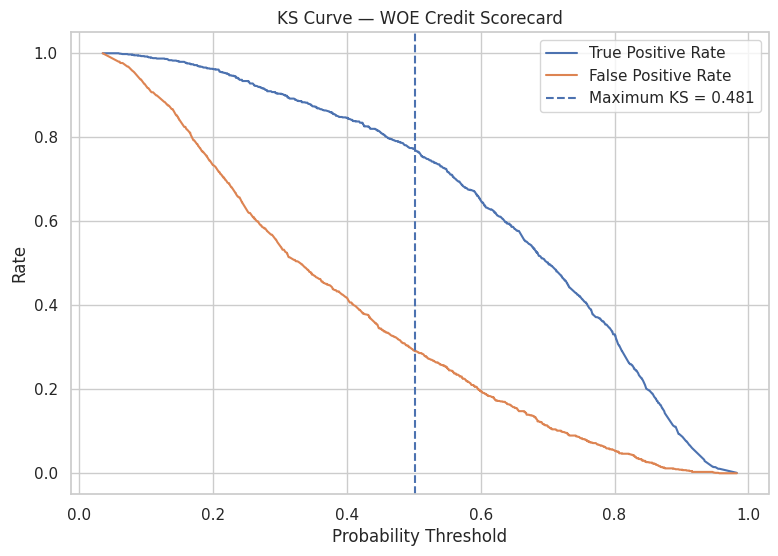

In [ ]:
# ============================================================
# KS CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    thresholds_ks,
    tpr,
    label="True Positive Rate"
)

plt.plot(
    thresholds_ks,
    fpr,
    label="False Positive Rate"
)

plt.axvline(
    ks_threshold,
    linestyle="--",
    label=f"Maximum KS = {ks_statistic:.3f}"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Rate")
plt.title("KS Curve — WOE Credit Scorecard")
plt.legend()
plt.show()

In [ ]:
# ============================================================
# DECILE ANALYSIS
# ============================================================

decile_data = pd.DataFrame({
    "Actual_Bad": y_test_sc.values,
    "Predicted_PD": scorecard_test_prob,
    "Credit_Score": scorecard_test_score
})

# Highest risk first
decile_data = decile_data.sort_values(
    "Predicted_PD",
    ascending=False
).reset_index(drop=True)

# Create 10 approximately equal-sized groups
decile_data["Decile"] = pd.qcut(
    decile_data.index,
    q=10,
    labels=False
) + 1

decile_summary = (
    decile_data
    .groupby("Decile")
    .agg(
        Applicants=("Actual_Bad", "count"),
        Average_Score=("Credit_Score", "mean"),
        Average_PD=("Predicted_PD", "mean"),
        Actual_Bad_Rate=("Actual_Bad", "mean")
    )
    .reset_index()
)

decile_summary["Average_PD_%"] = (
    decile_summary["Average_PD"] * 100
)

decile_summary["Actual_Bad_Rate_%"] = (
    decile_summary["Actual_Bad_Rate"] * 100
)

print("DECILE VALIDATION")
display(
    decile_summary[
        [
            "Decile",
            "Applicants",
            "Average_Score",
            "Average_PD_%",
            "Actual_Bad_Rate_%"
        ]
    ]
)

DECILE VALIDATION


,Decile,Applicants,Average_Score,Average_PD_%,Actual_Bad_Rate_%
0,1,198,435.596676,90.387575,90.404040
1,2,197,456.251118,82.845836,82.741117
2,3,198,469.257511,75.498344,77.272727
3,4,197,481.106314,67.205018,67.512690
4,5,198,491.817959,58.596147,59.595960
5,6,197,502.947601,49.063147,49.238579
6,7,197,515.275745,38.632809,34.010152
7,8,198,528.864352,28.244991,26.767677
8,9,197,541.681741,20.204897,20.304569
9,10,198,564.027563,10.936870,12.626263


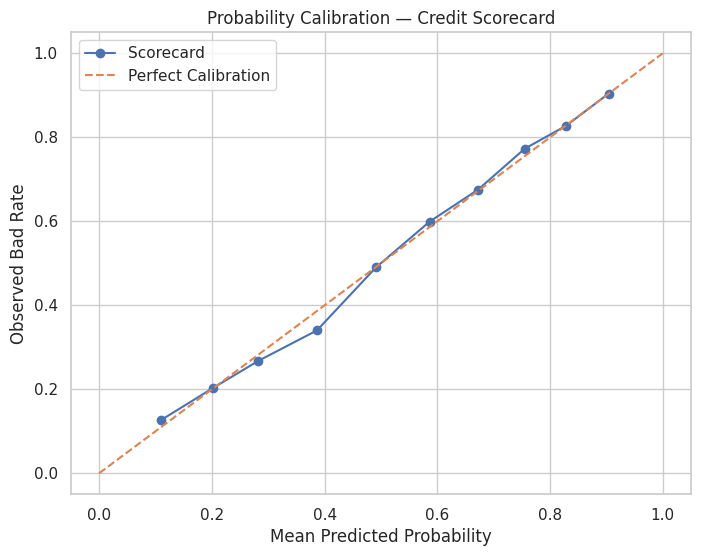

In [ ]:
# ============================================================
# CALIBRATION CURVE
# ============================================================

from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test_sc,
    scorecard_test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Scorecard"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Bad Rate")
plt.title("Probability Calibration — Credit Scorecard")
plt.legend()
plt.show()

In [ ]:
# ============================================================
# SIGMOID CALIBRATION
# ============================================================

from sklearn.calibration import CalibratedClassifierCV

calibrated_scorecard = CalibratedClassifierCV(
    estimator=scorecard_lr,
    method="sigmoid",
    cv=5
)

calibrated_scorecard.fit(
    X_train_woe[selected_features],
    y_train_sc
)

calibrated_train_prob = calibrated_scorecard.predict_proba(
    X_train_woe[selected_features]
)[:, 1]

calibrated_test_prob = calibrated_scorecard.predict_proba(
    X_test_woe[selected_features]
)[:, 1]

print("Calibration completed.")

print(
    "\nCalibrated Test ROC-AUC:",
    round(
        roc_auc_score(
            y_test_sc,
            calibrated_test_prob
        ),
        4
    )
)

print(
    "Calibrated Brier Score:",
    round(
        brier_score_loss(
            y_test_sc,
            calibrated_test_prob
        ),
        4
    )
)

Calibration completed.

Calibrated Test ROC-AUC: 0.8028
Calibrated Brier Score: 0.1808


In [ ]:
# ============================================================
# PORTFOLIO BASE-RATE ADJUSTMENT
# ============================================================

# IMPORTANT:
# This is an illustrative portfolio assumption.
# Replace it with an actual portfolio default rate
# if such information becomes available.

ASSUMED_PORTFOLIO_BAD_RATE = 0.20

TRAIN_BAD_RATE = y_train_sc.mean()

def adjust_probability_to_base_rate(
    probabilities,
    train_bad_rate,
    target_bad_rate
):

    probabilities = np.clip(
        probabilities,
        0.0001,
        0.9999
    )

    logit_model = np.log(
        probabilities / (1 - probabilities)
    )

    logit_adjustment = (
        np.log(
            target_bad_rate /
            (1 - target_bad_rate)
        )
        -
        np.log(
            train_bad_rate /
            (1 - train_bad_rate)
        )
    )

    adjusted_logit = (
        logit_model +
        logit_adjustment
    )

    adjusted_probability = (
        1 /
        (1 + np.exp(-adjusted_logit))
    )

    return adjusted_probability


portfolio_adjusted_pd = (
    adjust_probability_to_base_rate(
        calibrated_test_prob,
        TRAIN_BAD_RATE,
        ASSUMED_PORTFOLIO_BAD_RATE
    )
)

print("Development-set Bad rate:",
      round(TRAIN_BAD_RATE, 4))

print("Assumed portfolio Bad rate:",
      ASSUMED_PORTFOLIO_BAD_RATE)

print(
    "\nAverage calibrated PD:",
    round(calibrated_test_prob.mean(), 4)
)

print(
    "Average adjusted PD:",
    round(portfolio_adjusted_pd.mean(), 4)
)

Development-set Bad rate: 0.5203
Assumed portfolio Bad rate: 0.2

Average calibrated PD: 0.5216
Average adjusted PD: 0.2657


In [ ]:
# ============================================================
# COST-THRESHOLD SENSITIVITY
# ============================================================

cost_scenarios = {
    "Low Loss": {
        "bad_approved": 3,
        "good_rejected": 1
    },

    "Base Case": {
        "bad_approved": 5,
        "good_rejected": 1
    },

    "High Loss": {
        "bad_approved": 10,
        "good_rejected": 1
    }
}


threshold_grid = np.arange(
    0.05,
    0.91,
    0.01
)

sensitivity_results = []

for scenario, costs in cost_scenarios.items():

    scenario_costs = []

    for threshold in threshold_grid:

        cost = calculate_expected_cost(
            y_train_sc,
            calibrated_train_prob,
            threshold,
            cost_bad_approved=costs["bad_approved"],
            cost_good_rejected=costs["good_rejected"]
        )

        scenario_costs.append(cost)

    min_index = np.argmin(
        scenario_costs
    )

    best_threshold = threshold_grid[
        min_index
    ]

    sensitivity_results.append({
        "Scenario": scenario,
        "Bad Approved Cost": costs["bad_approved"],
        "Good Rejected Cost": costs["good_rejected"],
        "Optimal Threshold": best_threshold,
        "Minimum Training Cost": scenario_costs[min_index]
    })


cost_sensitivity_table = pd.DataFrame(
    sensitivity_results
)

display(cost_sensitivity_table)

,Scenario,Bad Approved Cost,Good Rejected Cost,Optimal Threshold,Minimum Training Cost
0,Low Loss,3,1,0.29,3126
1,Base Case,5,1,0.19,3455
2,High Loss,10,1,0.09,3713


In [ ]:
# ============================================================
# NO-HIT APPLICANT POLICY
# ============================================================

NO_HIT_POLICY = {
    "Condition": "All 23 bureau variables = -9",
    "Applicants_in_development_data": len(df_no_hit),
    "Good": int((df_no_hit["Target_Binary"] == 0).sum()),
    "Bad": int((df_no_hit["Target_Binary"] == 1).sum()),
    "Observed_Bad_Rate": df_no_hit["Target_Binary"].mean(),
    "Recommended_System_Action": "Manual Review / Alternative Verification"
}

no_hit_policy_table = pd.DataFrame([
    NO_HIT_POLICY
])

display(no_hit_policy_table)

,Condition,Applicants_in_development_data,Good,Bad,Observed_Bad_Rate,Recommended_System_Action
0,All 23 bureau variables = -9,588,265,323,0.54932,Manual Review / Alternative Verification


In [ ]:
# ============================================================
# SHAP EXPLAINABILITY
# ============================================================

import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [ ]:
# ============================================================
# CREATE SHAP EXPLAINER
# ============================================================

# Extract the trained XGBoost model
xgb_model = xgb_pipeline.named_steps["model"]

# Impute the test data using the fitted pipeline imputer
xgb_imputer = xgb_pipeline.named_steps["imputer"]

X_test_xgb_imputed = pd.DataFrame(
    xgb_imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_test_xgb_imputed
)

print("SHAP values calculated.")
print("Shape:", shap_values.shape)

SHAP values calculated.
Shape: (1975, 35)


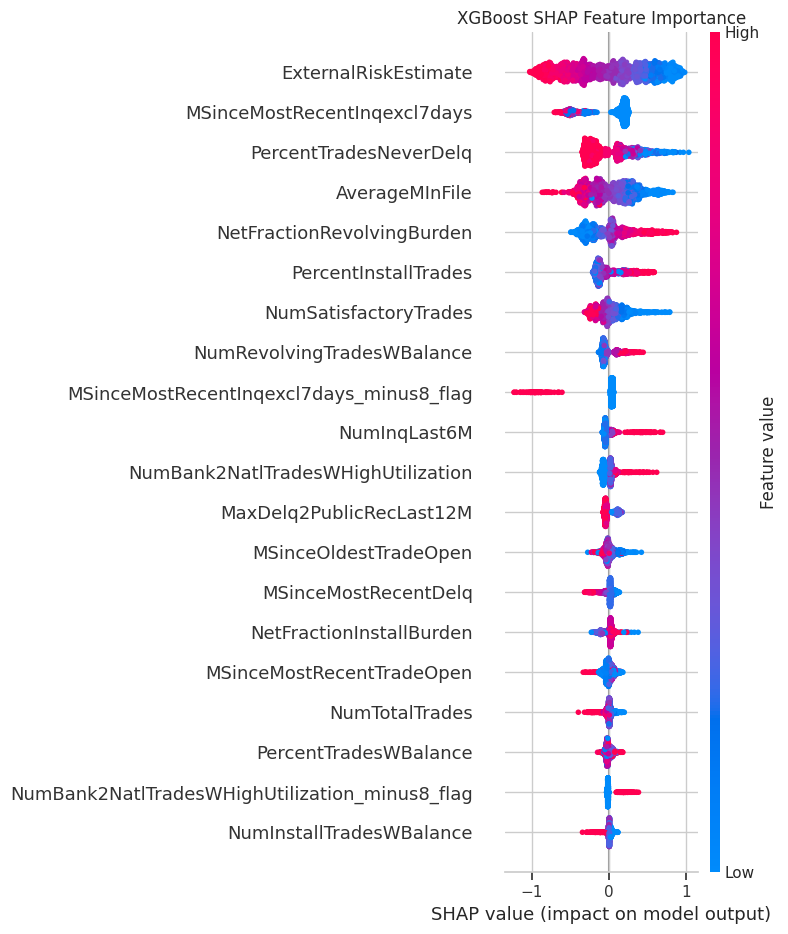

In [ ]:
# ============================================================
# SHAP SUMMARY PLOT
# ============================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test_xgb_imputed,
    show=False
)

plt.title(
    "XGBoost SHAP Feature Importance"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# SHAP FEATURE IMPORTANCE
# ============================================================

shap_importance = pd.DataFrame({
    "Feature": X_test_xgb_imputed.columns,
    "Mean_Absolute_SHAP": np.abs(
        shap_values
    ).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    shap_importance.head(15)
)

,Feature,Mean_Absolute_SHAP
0,ExternalRiskEstimate,0.467164
1,MSinceMostRecentInqexcl7days,0.270904
2,PercentTradesNeverDelq,0.253598
3,AverageMInFile,0.248556
4,NetFractionRevolvingBurden,0.226098
5,PercentInstallTrades,0.150203
6,NumSatisfactoryTrades,0.131831
7,NumRevolvingTradesWBalance,0.086948
8,MSinceMostRecentInqexcl7days_minus8_flag,0.085826
9,NumInqLast6M,0.060471


In [ ]:
# ============================================================
# FINAL APPLICANT DEMO
# ============================================================

demo_output = pd.DataFrame({
    "Credit_Score": scorecard_test_score,
    "Model_PD": scorecard_test_prob,
    "Calibrated_PD": calibrated_test_prob,
    "Portfolio_Adjusted_PD": portfolio_adjusted_pd,
    "Risk_Band": test_risk_band.values,
    "Decision": decision_results["Final_Decision"].values,
    "Actual_Bad": y_test_sc.values
}, index=X_test_sc.index)

demo_output = pd.concat(
    [
        demo_output,
        reason_codes
    ],
    axis=1
)

demo_output["Credit_Score"] = (
    demo_output["Credit_Score"].round(1)
)

demo_output["Model_PD"] = (
    demo_output["Model_PD"].round(4)
)

demo_output["Calibrated_PD"] = (
    demo_output["Calibrated_PD"].round(4)
)

demo_output["Portfolio_Adjusted_PD"] = (
    demo_output["Portfolio_Adjusted_PD"].round(4)
)

demo_output.head()

,Credit_Score,Model_PD,Calibrated_PD,Portfolio_Adjusted_PD,Risk_Band,Decision,Actual_Bad,Reason_1,Reason_2,Reason_3
7695,486.1,0.6332,0.6298,0.2817,High Risk,Reject,1,ExternalRiskEstimate,AverageMInFile,NetFractionRevolvingBurden
9543,484.2,0.6485,0.6464,0.2964,High Risk,Reject,1,ExternalRiskEstimate,MSinceMostRecentInqexcl7days,NetFractionRevolvingBurden
2719,448.0,0.8663,0.8606,0.5873,Review Zone,Reject,0,AverageMInFile,PercentTradesNeverDelq,NumSatisfactoryTrades
9203,528.9,0.2813,0.2855,0.0843,Medium Risk,Reject,0,PercentInstallTrades,MaxDelqEver,MSinceMostRecentInqexcl7days
8999,470.3,0.7492,0.7461,0.4038,High Risk,Reject,1,AverageMInFile,NetFractionRevolvingBurden,ExternalRiskEstimate


In [ ]:
# ============================================================
# FINAL APPLICANT DEMO
# ============================================================

demo_output = pd.DataFrame({
    "Credit_Score": scorecard_test_score,
    "Model_PD": scorecard_test_prob,
    "Calibrated_PD": calibrated_test_prob,
    "Portfolio_Adjusted_PD": portfolio_adjusted_pd,
    "Risk_Band": test_risk_band.values,
    "Decision": decision_results["Final_Decision"].values,
    "Actual_Bad": y_test_sc.values
}, index=X_test_sc.index)

demo_output = pd.concat(
    [
        demo_output,
        reason_codes
    ],
    axis=1
)

demo_output["Credit_Score"] = (
    demo_output["Credit_Score"].round(1)
)

demo_output["Model_PD"] = (
    demo_output["Model_PD"].round(4)
)

demo_output["Calibrated_PD"] = (
    demo_output["Calibrated_PD"].round(4)
)

demo_output["Portfolio_Adjusted_PD"] = (
    demo_output["Portfolio_Adjusted_PD"].round(4)
)

demo_output.head()

,Credit_Score,Model_PD,Calibrated_PD,Portfolio_Adjusted_PD,Risk_Band,Decision,Actual_Bad,Reason_1,Reason_2,Reason_3
7695,486.1,0.6332,0.6298,0.2817,High Risk,Reject,1,ExternalRiskEstimate,AverageMInFile,NetFractionRevolvingBurden
9543,484.2,0.6485,0.6464,0.2964,High Risk,Reject,1,ExternalRiskEstimate,MSinceMostRecentInqexcl7days,NetFractionRevolvingBurden
2719,448.0,0.8663,0.8606,0.5873,Review Zone,Reject,0,AverageMInFile,PercentTradesNeverDelq,NumSatisfactoryTrades
9203,528.9,0.2813,0.2855,0.0843,Medium Risk,Reject,0,PercentInstallTrades,MaxDelqEver,MSinceMostRecentInqexcl7days
8999,470.3,0.7492,0.7461,0.4038,High Risk,Reject,1,AverageMInFile,NetFractionRevolvingBurden,ExternalRiskEstimate


In [ ]:
# ============================================================
# INDIVIDUAL APPLICANT ASSESSMENT
# ============================================================

applicant_id = demo_output.index[0]

applicant = demo_output.loc[
    applicant_id
]

print("================================================")
print("         CREDIT RISK ASSESSMENT")
print("================================================")

print("\nApplicant ID:", applicant_id)

print(
    "\nCredit Score:",
    applicant["Credit_Score"]
)

print(
    "Model Probability of Default:",
    f"{applicant['Model_PD']:.2%}"
)

print(
    "Calibrated Probability of Default:",
    f"{applicant['Calibrated_PD']:.2%}"
)

print(
    "Portfolio-Adjusted PD:",
    f"{applicant['Portfolio_Adjusted_PD']:.2%}"
)

print(
    "\nRisk Band:",
    applicant["Risk_Band"]
)

print(
    "Decision:",
    applicant["Decision"]
)

print("\nTop Reason Codes:")

print("1.", applicant["Reason_1"])
print("2.", applicant["Reason_2"])
print("3.", applicant["Reason_3"])

print("\n================================================")

         CREDIT RISK ASSESSMENT

Applicant ID: 7695

Credit Score: 486.1
Model Probability of Default: 63.32%
Calibrated Probability of Default: 62.98%
Portfolio-Adjusted PD: 28.17%

Risk Band: High Risk
Decision: Reject

Top Reason Codes:
1. ExternalRiskEstimate
2. AverageMInFile
3. NetFractionRevolvingBurden



In [ ]:
# ============================================================
# FINAL MASTER MODEL COMPARISON
# ============================================================

master_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression Baseline",
        "XGBoost Challenger",
        "WOE Credit Scorecard"
    ],

    "Test ROC-AUC": [
        roc_auc_score(y_test, lr_prob),
        roc_auc_score(y_test, xgb_prob),
        roc_auc_score(y_test_sc, scorecard_test_prob)
    ],

    "Gini": [
        2 * roc_auc_score(y_test, lr_prob) - 1,
        2 * roc_auc_score(y_test, xgb_prob) - 1,
        2 * roc_auc_score(y_test_sc, scorecard_test_prob) - 1
    ],

    "Brier Score": [
        brier_score_loss(y_test, lr_prob),
        brier_score_loss(y_test, xgb_prob),
        brier_score_loss(y_test_sc, scorecard_test_prob)
    ],

    "Role": [
        "Baseline",
        "Challenger / Nonlinear Model",
        "Primary Explainable Scorecard"
    ]
})

display(
    master_model_comparison.round(4)
)

,Model,Test ROC-AUC,Gini,Brier Score,Role
0,Logistic Regression Baseline,0.8087,0.6173,0.1783,Baseline
1,XGBoost Challenger,0.8077,0.6154,0.1784,Challenger / Nonlinear Model
2,WOE Credit Scorecard,0.8029,0.6058,0.1807,Primary Explainable Scorecard


In [ ]:
# ============================================================
# SAVE FINAL PROJECT OUTPUTS
# ============================================================

final_applicant_output.to_csv(
    "final_credit_decisions.csv"
)

risk_summary_table.to_csv(
    "risk_band_validation.csv",
    index=False
)

decile_summary.to_csv(
    "scorecard_decile_analysis.csv",
    index=False
)

cost_sensitivity_table.to_csv(
    "cost_threshold_sensitivity.csv",
    index=False
)

shap_importance.to_csv(
    "xgboost_shap_importance.csv",
    index=False
)

master_model_comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("All final project outputs saved successfully.")

All final project outputs saved successfully.
